# RIHA — Freedom Without Fear
## Global Women's Safety & Equality Analytics

### Project Overview
RIHA is a data analysis project focused on exploring global patterns in women's safety, gender equality, and empowerment.

The project uses publicly available data from reliable sources to examine trends, compare selected indicators, and identify data-quality issues.

### Objectives
1. Explore datasets related to women's safety and equality.
2. Identify missing values, duplicates, and data-quality issues.
3. Clean and prepare the data for analysis.
4. Perform exploratory data analysis using Pandas and NumPy.
5. Create meaningful visualizations.
6. Present evidence-based findings and recommendations.

### Important Note
Reported incidents and estimated prevalence are different measures. Differences in definitions, survey methods, and reporting practices must be considered when comparing countries.

In [1908]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("RIHA — Freedom Without Fear")
print("All libraries imported successfully!")


RIHA — Freedom Without Fear
All libraries imported successfully!


In [1909]:
from pathlib import Path
DATA_FOLDER = Path(r"D:\Rihaa\data\raw")

files = list(DATA_FOLDER.iterdir())

print("RIHA — Available Data Files")
print("-" * 40)

for file in files:
    print(file.name)

RIHA — Available Data Files
----------------------------------------
Contextual Indicators.csv
Contextual_Indicators.csv
Gender_Statscountry-series.csv
Gender_StatsCountry.csv
Gender_StatsCSV.csv
Gender_Statsfootnote.csv
Gender_Statsseries-time.csv
Gender_StatsSeries.csv
Metadata.csv
Proportion of women who have ever experienced intimate partner violence (% of ever-partnered women ages 15-49).csv
violence.csv
Violence_against_women_prevalence_estimates_2023.pdf


In [1910]:
file_path = DATA_FOLDER / "Gender_StatsCSV.csv"
df = pd.read_csv(file_path, low_memory=False)
df.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Africa Eastern and Southern,AFE,"About one month can be covered using savings, ...",fin24bb,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,"About one month can be covered using savings, ...",fin24bb.2,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Africa Eastern and Southern,AFE,"About one month can be covered using savings, ...",fin24bb.1,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Africa Eastern and Southern,AFE,"About two months can be covered using savings,...",fin24bc,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Africa Eastern and Southern,AFE,"About two months can be covered using savings,...",fin24bc.2,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [1911]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isnull().sum())

Dataset shape: (372504, 70)

Column names:
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']

Data types:
Country Name          str
Country Code          str
Indicator Name        str
Indicator Code        str
1960              float64
                   ...   
2021              float64
2022              float64
2023              float64
2024              float64
2025              float64
Length: 70, dtype: object

Missing values in each column:
Cou

In [1912]:
keywords = [
    "violence against women",
    "intimate partner violence",
    "sexual violence",
    "rape",
    "gender-based violence",
    "physical violence",
    "women who have experienced"
]

for keyword in keywords:
    matches = df[
        df["Indicator Name"].str.contains(
            keyword, case=False, na=False, regex=False
        )
    ]

    print(f"\n{'=' * 60}")
    print(f"Keyword: {keyword}")
    print(f"Matching rows: {len(matches)}")

    if not matches.empty:
        print(
            matches[
                ["Indicator Name", "Indicator Code"]
            ].drop_duplicates().head(10).to_string(index=False)
        )


Keyword: violence against women
Matching rows: 792
                                                                                                                                                                Indicator Name          Indicator Code
                                                   WBL: Supportive Framework, Safety, There are mechanisms to facilitate access to justice for cases of violence against women GD_WBL_SAF_SFR_AJUSTICE
                                                                              WBL: Supportive Framework, Safety, There is an action plan or strategy on violence against women   GD_WBL_SAF_SFR_ACTPLN
WBL: Supportive Framework, Safety, There is an institutional mechanism to monitor the implementation of legislation, national plans, and/or programs on violence against women  GD_WBL_SAF_SFR_MONITOR

Keyword: intimate partner violence
Matching rows: 3696
                                                                                                

In [1913]:
selected_codes = [
    "SG.VAW.15PL.LT.ME.ZS",
    "SG.VAW.15PL.ME.ZS",
    "SG.VAW.IPPV.LT.ZS"
]

riha_data = df[
    df["Indicator Code"].isin(selected_codes)
].copy()

print("RIHA — Selected Violence Indicators")
print("-" * 50)

print(
    riha_data[
        ["Country Name", "Indicator Name", "Indicator Code"]
    ]
    .drop_duplicates()
    .head(15)
    .to_string(index=False)
)

print("\nDataset shape:", riha_data.shape)

print("\nRows per indicator:")
print(riha_data["Indicator Code"].value_counts())

RIHA — Selected Violence Indicators
--------------------------------------------------
                  Country Name                                                                                                                                Indicator Name       Indicator Code
   Africa Eastern and Southern Proportion of women subjected to physical and/or sexual violence in the last 12 months (modeled estimate, % of ever partnered women ages 15+)    SG.VAW.15PL.ME.ZS
   Africa Eastern and Southern                Proportion of women who have ever experienced intimate partner violence (modeled estimate, % of ever partnered women ages 15+) SG.VAW.15PL.LT.ME.ZS
   Africa Eastern and Southern                     Women who have ever experienced physical violence committed by their husband/partner (% of ever-married women ages 15-49)    SG.VAW.IPPV.LT.ZS
    Africa Western and Central Proportion of women subjected to physical and/or sexual violence in the last 12 months (modeled estimate, 

In [1914]:
year_columns = [
    col for col in df.columns
    if col.isdigit() and len(col) == 4
]
year_summary = riha_data[year_columns].notna().sum()

print("Available observations by year:")
print(year_summary[year_summary > 0].to_string())

Available observations by year:
2000      4
2002      1
2003      1
2004      2
2005      4
2006      7
2007      7
2008      4
2009      3
2010      7
2011      6
2012      9
2013      8
2014      6
2015      6
2016     10
2017      6
2018      9
2019      2
2020      3
2021      6
2022      6
2023    360


In [1915]:
riha_2023 = riha_data[
    [
        "Country Name",
        "Country Code",
        "Indicator Name",
        "Indicator Code",
        "2023"
    ]
].copy()
riha_2023 = riha_2023.rename(
    columns={"2023": "Value"}
)
print("Missing 2023 values before cleaning:")
print(riha_2023["Value"].isna().sum())
riha_2023 = riha_2023.dropna(subset=["Value"]).copy()
duplicates = riha_2023.duplicated(
    subset=["Country Code", "Indicator Code"]
).sum()

print("\nRows after removing missing values:", len(riha_2023))
print("Duplicate country-indicator combinations:", duplicates)
riha_2023.head(10)

Missing 2023 values before cleaning:
432

Rows after removing missing values: 360
Duplicate country-indicator combinations: 0


,Country Name,Country Code,Indicator Name,Indicator Code,Value
9210,East Asia & Pacific,EAS,Proportion of women subjected to physical and/...,SG.VAW.15PL.ME.ZS,8.1
9251,East Asia & Pacific,EAS,Proportion of women who have ever experienced ...,SG.VAW.15PL.LT.ME.ZS,18.2
10621,East Asia & Pacific (excluding high income),EAP,Proportion of women subjected to physical and/...,SG.VAW.15PL.ME.ZS,8.5
10662,East Asia & Pacific (excluding high income),EAP,Proportion of women who have ever experienced ...,SG.VAW.15PL.LT.ME.ZS,18.7
14854,Europe & Central Asia,ECS,Proportion of women subjected to physical and/...,SG.VAW.15PL.ME.ZS,5.5
14895,Europe & Central Asia,ECS,Proportion of women who have ever experienced ...,SG.VAW.15PL.LT.ME.ZS,20.8
16265,Europe & Central Asia (excluding high income),ECA,Proportion of women subjected to physical and/...,SG.VAW.15PL.ME.ZS,9.3
16306,Europe & Central Asia (excluding high income),ECA,Proportion of women who have ever experienced ...,SG.VAW.15PL.LT.ME.ZS,28.2
21909,High income,HIC,Proportion of women subjected to physical and/...,SG.VAW.15PL.ME.ZS,5.3
21950,High income,HIC,Proportion of women who have ever experienced ...,SG.VAW.15PL.LT.ME.ZS,20.4


In [1916]:
print("Unique country/region names:", riha_2023["Country Name"].nunique())

print("\nFirst 30 unique entries:")
print(
    sorted(riha_2023["Country Name"].unique())[:30]
)

Unique country/region names: 184

First 30 unique entries:
['Afghanistan', 'Albania', 'Angola', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas, The', 'Bangladesh', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bhutan', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cabo Verde', 'Cambodia', 'Cameroon', 'Canada', 'Central African Republic', 'Chad', 'Chile', 'China']


In [1917]:

country_file = DATA_FOLDER / "Gender_StatsCountry.csv"

countries = pd.read_csv(country_file, low_memory=False)

print("Country metadata shape:", countries.shape)

print("\nColumn names:")
print(countries.columns.tolist())

print("\nFirst five rows:")
display(countries.head())

Country metadata shape: (264, 31)

Column names:
['Country Code', 'Short Name', 'Table Name', 'Long Name', '2-alpha code', 'Currency Unit', 'Special Notes', 'Region', 'Income Group', 'WB-2 code', 'National accounts base year', 'National accounts reference year', 'SNA price valuation', 'Lending category', 'Other groups', 'System of National Accounts', 'Alternative conversion factor', 'PPP survey year', 'Balance of Payments Manual in use', 'External debt Reporting status', 'System of trade', 'Government Accounting concept', 'IMF data dissemination standard', 'Latest population census', 'Latest household survey', 'Source of most recent Income and expenditure data', 'Vital registration complete', 'Latest agricultural census', 'Latest industrial data', 'Latest trade data', 'Latest water withdrawal data']

First five rows:


,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,...,Government Accounting concept,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,NaN,Latin America & Caribbean,High income,AW,...,NaN,Enhanced General Data Dissemination System (e-...,2020 (expected),NaN,NaN,Yes,NaN,NaN,2018.0,NaN
1,AFE,Africa Eastern and Southern,Africa Eastern and Southern,Africa Eastern and Southern,ZH,NaN,"26 countries, stretching from the Red Sea in t...",NaN,NaN,ZH,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,The reporting period for national accounts dat...,Middle East & North Africa,Low income,AF,...,Consolidated central government,Enhanced General Data Dissemination System (e-...,1979,Multiple Indicator Cluster Survey 2022-2023,"Integrated household survey (IHS), 2016/17",NaN,2003.0,NaN,2018.0,2000.0
3,AFW,Africa Western and Central,Africa Western and Central,Africa Western and Central,ZI,NaN,"22 countries, stretching from the westernmost ...",NaN,NaN,ZI,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,The World Bank systematically assesses the app...,Sub-Saharan Africa,Lower middle income,AO,...,Budgetary central government,Enhanced General Data Dissemination System (e-...,2014,Inquérito de Indicadores Múltiplos e de Saúde ...,"Integrated household survey (IHS), 2008/09",NaN,2023.0,NaN,2018.0,2005.0


In [1918]:
country_list = countries.loc[
    countries["Region"].notna()
    & countries["Income Group"].notna(),
    ["Country Code", "Short Name", "Region", "Income Group"]
].copy()

print("Number of country entries:", len(country_list))
riha_countries_2023 = riha_2023.merge(
    country_list,
    on="Country Code",
    how="inner"
)

print("\nCountry-level observations:", len(riha_countries_2023))

print("\nObservations by indicator:")
print(
    riha_countries_2023["Indicator Code"].value_counts()
)

display(riha_countries_2023.head(10))

Number of country entries: 217

Country-level observations: 326

Observations by indicator:
Indicator Code
SG.VAW.15PL.ME.ZS       163
SG.VAW.15PL.LT.ME.ZS    162
SG.VAW.IPPV.LT.ZS         1
Name: count, dtype: int64


,Country Name,Country Code,Indicator Name,Indicator Code,Value,Short Name,Region,Income Group
0,Afghanistan,AFG,Proportion of women subjected to physical and/...,SG.VAW.15PL.ME.ZS,35.1,Afghanistan,Middle East & North Africa,Low income
1,Afghanistan,AFG,Proportion of women who have ever experienced ...,SG.VAW.15PL.LT.ME.ZS,50.7,Afghanistan,Middle East & North Africa,Low income
2,Albania,ALB,Proportion of women subjected to physical and/...,SG.VAW.15PL.ME.ZS,2.4,Albania,Europe & Central Asia,Upper middle income
3,Albania,ALB,Proportion of women who have ever experienced ...,SG.VAW.15PL.LT.ME.ZS,18.7,Albania,Europe & Central Asia,Upper middle income
4,Angola,AGO,Proportion of women subjected to physical and/...,SG.VAW.15PL.ME.ZS,20.6,Angola,Sub-Saharan Africa,Lower middle income
5,Angola,AGO,Proportion of women who have ever experienced ...,SG.VAW.15PL.LT.ME.ZS,33.7,Angola,Sub-Saharan Africa,Lower middle income
6,Argentina,ARG,Proportion of women subjected to physical and/...,SG.VAW.15PL.ME.ZS,9.6,Argentina,Latin America & Caribbean,Upper middle income
7,Argentina,ARG,Proportion of women who have ever experienced ...,SG.VAW.15PL.LT.ME.ZS,34.8,Argentina,Latin America & Caribbean,Upper middle income
8,Armenia,ARM,Proportion of women subjected to physical and/...,SG.VAW.15PL.ME.ZS,3.2,Armenia,Europe & Central Asia,Upper middle income
9,Armenia,ARM,Proportion of women who have ever experienced ...,SG.VAW.15PL.LT.ME.ZS,9.0,Armenia,Europe & Central Asia,Upper middle income


In [1919]:
print("Dataset shape:", riha_countries_2023.shape)

print("\nMissing values:")
print(riha_countries_2023.isnull().sum())

print("\nDuplicate rows:", riha_countries_2023.duplicated().sum())

print("\nUnique countries:", riha_countries_2023["Country Code"].nunique())

print("\nObservations per indicator:")
print(riha_countries_2023["Indicator Code"].value_counts())

Dataset shape: (326, 8)

Missing values:
Country Name      0
Country Code      0
Indicator Name    0
Indicator Code    0
Value             0
Short Name        0
Region            0
Income Group      0
dtype: int64

Duplicate rows: 0

Unique countries: 167

Observations per indicator:
Indicator Code
SG.VAW.15PL.ME.ZS       163
SG.VAW.15PL.LT.ME.ZS    162
SG.VAW.IPPV.LT.ZS         1
Name: count, dtype: int64


In [1920]:
main_indicators = [
    "SG.VAW.15PL.ME.ZS",
    "SG.VAW.15PL.LT.ME.ZS"
]

eda_data = riha_countries_2023[
    riha_countries_2023["Indicator Code"].isin(main_indicators)
].copy()
summary = eda_data.groupby("Indicator Code")["Value"].describe()

display(summary)

,count,mean,std,min,25%,50%,75%,max
Indicator Code,,,,,,,,
SG.VAW.15PL.LT.ME.ZS,162.0,25.526543,12.395465,5.3,16.55,23.8,33.425,59.5
SG.VAW.15PL.ME.ZS,163.0,10.661350,8.800388,1.0,4.10,8.0,14.750,39.8


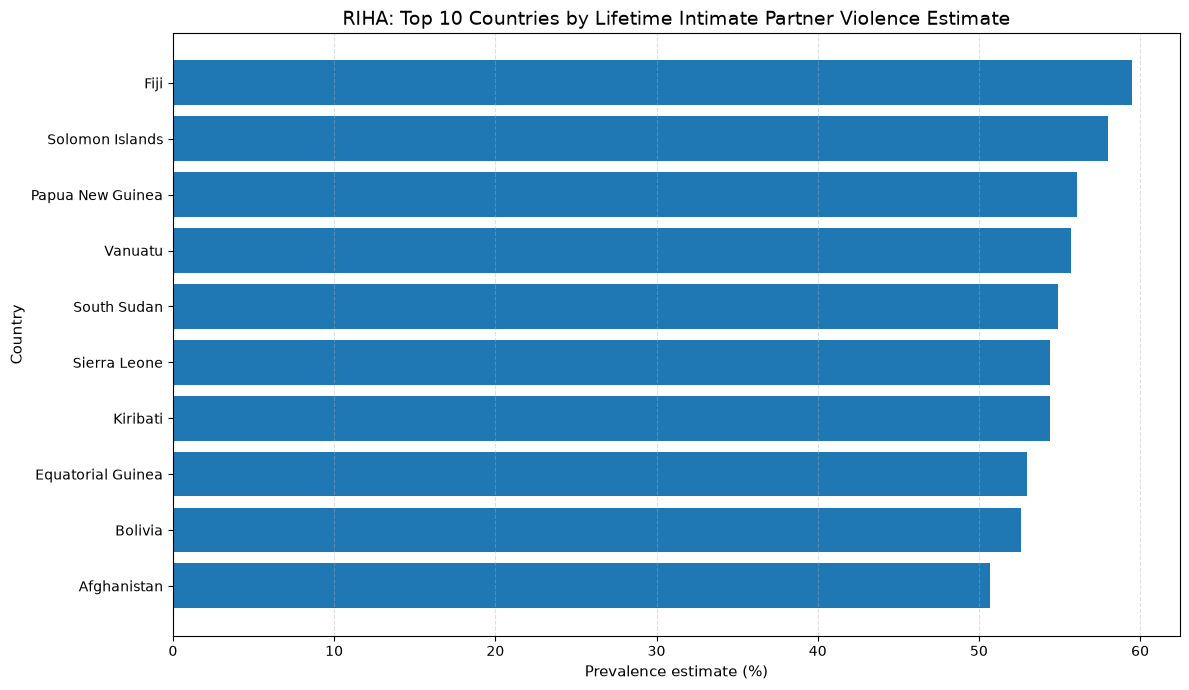

Chart saved successfully!


In [1921]:
lifetime_data = eda_data[
    eda_data["Indicator Code"] == "SG.VAW.15PL.LT.ME.ZS"
].copy()

top_10 = lifetime_data.nlargest(10, "Value").sort_values(
    "Value", ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_10["Country Name"],
    top_10["Value"]
)

plt.title(
    "RIHA: Top 10 Countries by Lifetime Intimate Partner Violence Estimate",
    fontsize=14
)

plt.xlabel("Prevalence estimate (%)", fontsize=11)
plt.ylabel("Country", fontsize=11)

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()

FIGURES_FOLDER = Path(r"D:\Rihaa\outputs\figures")
FIGURES_FOLDER.mkdir(parents=True, exist_ok=True)

plt.savefig(
    FIGURES_FOLDER / "top_10_lifetime_violence_estimates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")

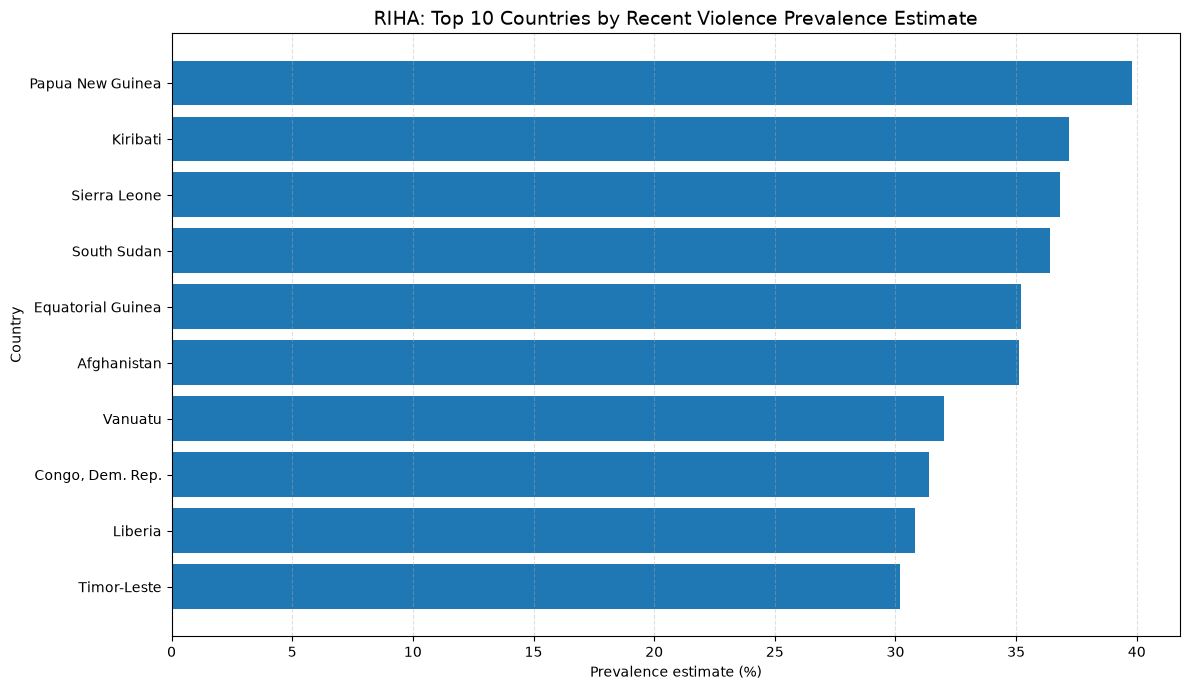

Second chart saved successfully!


In [1922]:
recent_data = eda_data[eda_data["Indicator Code"] == "SG.VAW.15PL.ME.ZS"].copy()
top_10_recent = recent_data.nlargest(10, "Value").sort_values("Value", ascending=True)
plt.figure(figsize=(12, 7))
plt.barh(top_10_recent["Country Name"], top_10_recent["Value"])
plt.title("RIHA: Top 10 Countries by Recent Violence Prevalence Estimate", fontsize=14)
plt.xlabel("Prevalence estimate (%)")
plt.ylabel("Country")
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(FIGURES_FOLDER / "top_10_recent_violence_estimates.png", dpi=300, bbox_inches="tight")
plt.show()
print("Second chart saved successfully!")

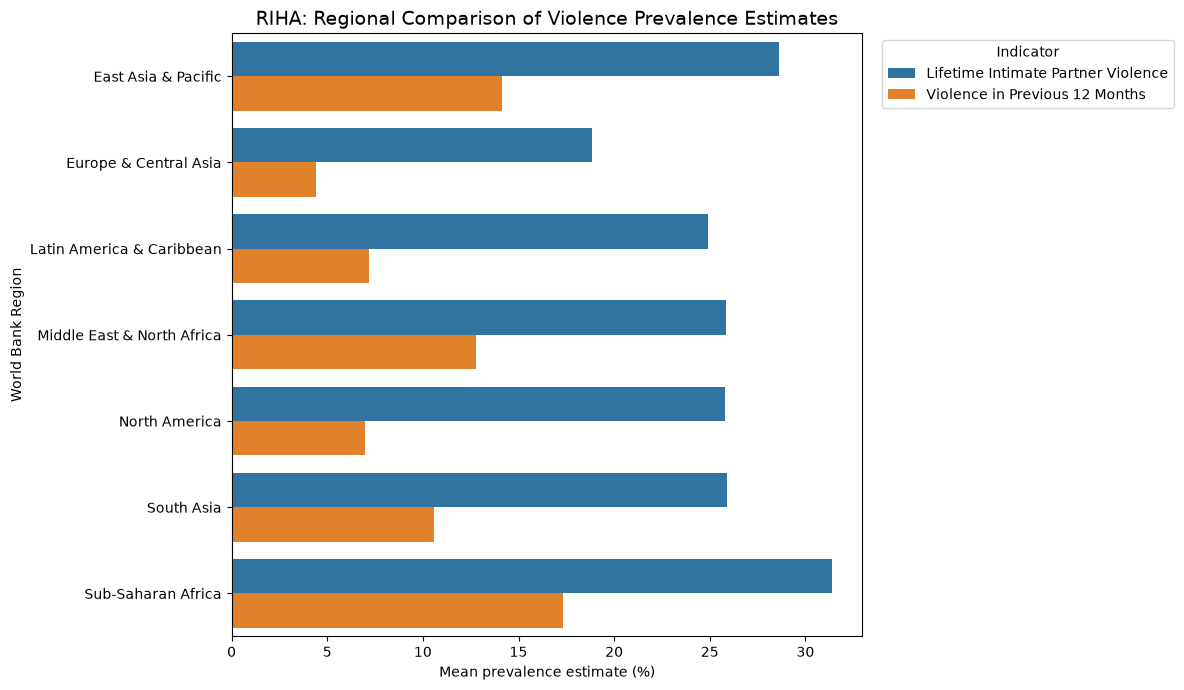

In [1923]:
regional_data = eda_data.groupby(["Region", "Indicator Code"])["Value"].mean().reset_index()
regional_data["Indicator"] = regional_data["Indicator Code"].map({
    "SG.VAW.15PL.LT.ME.ZS": "Lifetime Intimate Partner Violence",
    "SG.VAW.15PL.ME.ZS": "Violence in Previous 12 Months"
})
plt.figure(figsize=(12, 7))
sns.barplot(data=regional_data, x="Value", y="Region", hue="Indicator")
plt.title("RIHA: Regional Comparison of Violence Prevalence Estimates", fontsize=14)
plt.xlabel("Mean prevalence estimate (%)")
plt.ylabel("World Bank Region")
plt.legend(title="Indicator", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIGURES_FOLDER / "regional_violence_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

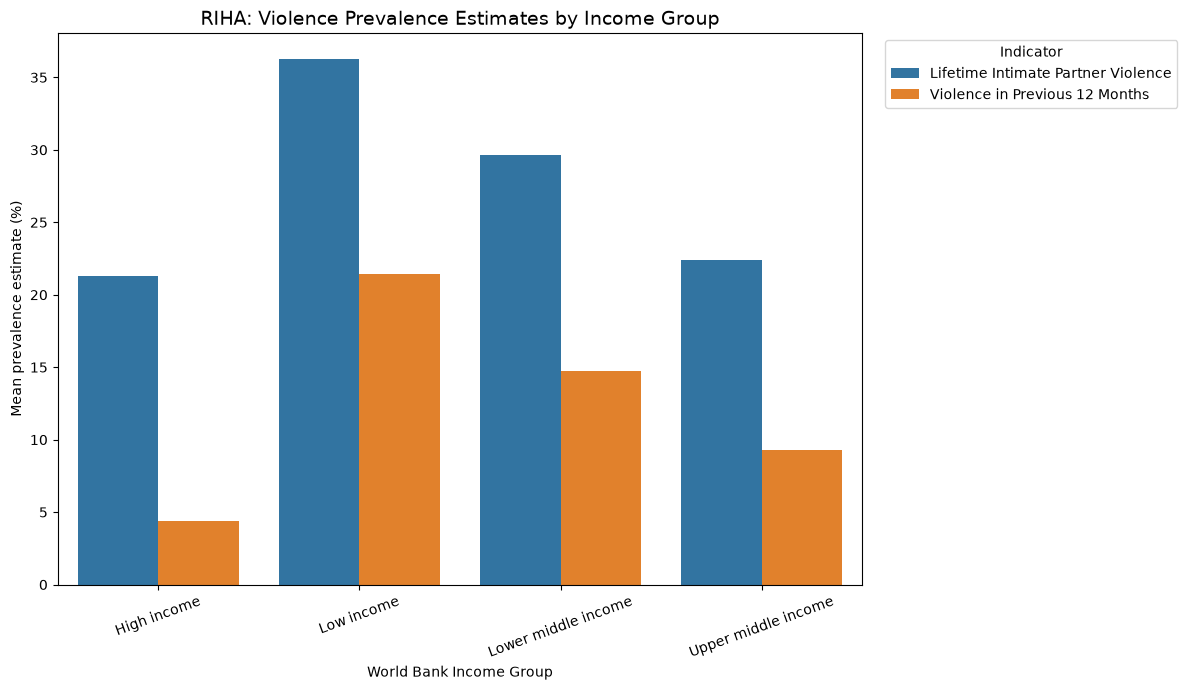

In [1924]:
income_data = eda_data.groupby(["Income Group", "Indicator Code"])["Value"].mean().reset_index()
income_data["Indicator"] = income_data["Indicator Code"].map({
    "SG.VAW.15PL.LT.ME.ZS": "Lifetime Intimate Partner Violence",
    "SG.VAW.15PL.ME.ZS": "Violence in Previous 12 Months"
})
plt.figure(figsize=(12, 7))
sns.barplot(data=income_data, x="Income Group", y="Value", hue="Indicator")
plt.title("RIHA: Violence Prevalence Estimates by Income Group", fontsize=14)
plt.xlabel("World Bank Income Group")
plt.ylabel("Mean prevalence estimate (%)")
plt.xticks(rotation=20)
plt.legend(title="Indicator", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIGURES_FOLDER / "income_group_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

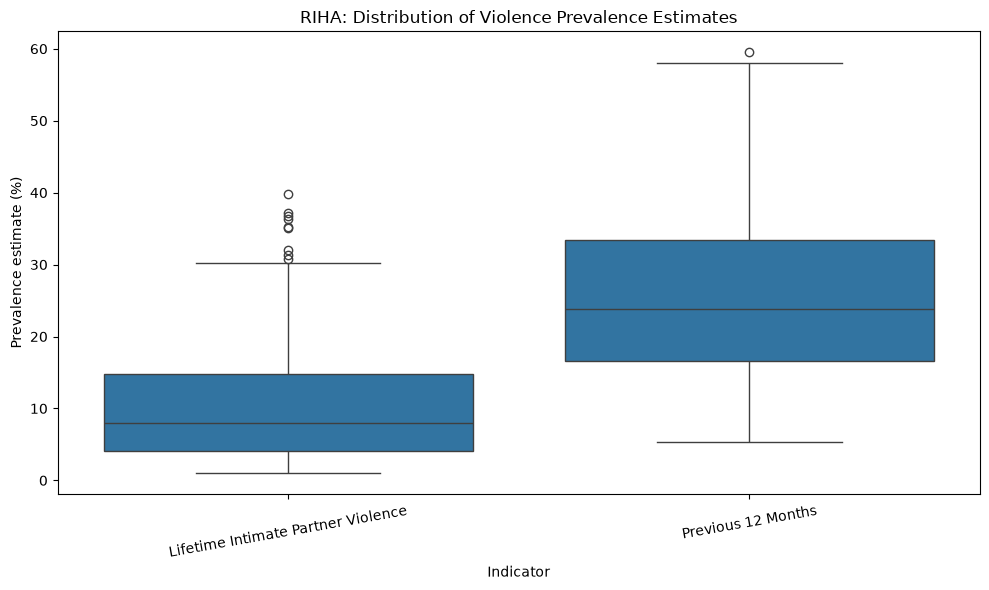

In [1925]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=eda_data, x="Indicator Code", y="Value")
plt.title("RIHA: Distribution of Violence Prevalence Estimates")
plt.xlabel("Indicator")
plt.ylabel("Prevalence estimate (%)")
plt.xticks(
    ticks=[0, 1],
    labels=["Lifetime Intimate Partner Violence", "Previous 12 Months"],
    rotation=10
)
plt.tight_layout()
plt.savefig(FIGURES_FOLDER / "violence_estimates_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()

In [1926]:
lifetime = eda_data[eda_data["Indicator Code"] == "SG.VAW.15PL.LT.ME.ZS"]
recent = eda_data[eda_data["Indicator Code"] == "SG.VAW.15PL.ME.ZS"]

print("RIHA — Global Women's Safety & Equality Analytics")
print("=" * 55)
print("\nLIFETIME INTIMATE PARTNER VIOLENCE")
print("Mean:", round(lifetime["Value"].mean(), 2), "%")
print("Median:", round(lifetime["Value"].median(), 2), "%")
print("Maximum:", round(lifetime["Value"].max(), 2), "%")
print("Country with highest estimate:")
display(lifetime.nlargest(1, "Value")[["Country Name", "Value"]])

print("\nPHYSICAL AND/OR SEXUAL VIOLENCE IN THE PREVIOUS 12 MONTHS")
print("Mean:", round(recent["Value"].mean(), 2), "%")
print("Median:", round(recent["Value"].median(), 2), "%")
print("Maximum:", round(recent["Value"].max(), 2), "%")
print("Country with highest estimate:")
display(recent.nlargest(1, "Value")[["Country Name", "Value"]])

RIHA — Global Women's Safety & Equality Analytics

LIFETIME INTIMATE PARTNER VIOLENCE
Mean: 25.53 %
Median: 23.8 %
Maximum: 59.5 %
Country with highest estimate:


,Country Name,Value
98,Fiji,59.5



PHYSICAL AND/OR SEXUAL VIOLENCE IN THE PREVIOUS 12 MONTHS
Mean: 10.66 %
Median: 8.0 %
Maximum: 39.8 %
Country with highest estimate:


,Country Name,Value
230,Papua New Guinea,39.8


In [1927]:
PROCESSED_FOLDER = Path(r"D:\Rihaa\data\processed")
PROCESSED_FOLDER.mkdir(parents=True, exist_ok=True)
riha_countries_2023.to_csv(PROCESSED_FOLDER / "riha_violence_data_2023.csv", index=False)
eda_data.to_csv(PROCESSED_FOLDER / "riha_analysis_data_2023.csv", index=False)
print("Cleaned datasets saved successfully!")

Cleaned datasets saved successfully!


In [1928]:
from pathlib import Path

folder = Path(r"D:\Rihaa")

for file in folder.rglob("*"):
    if file.is_file() and file.suffix.lower() in [".csv", ".xlsx", ".xls"]:
        print(file)

D:\Rihaa\outputs\figures\bottom10_countries.csv
D:\Rihaa\outputs\figures\riha_key_findings.csv
D:\Rihaa\outputs\figures\riha_summary_statistics.csv
D:\Rihaa\outputs\figures\top10_countries.csv
D:\Rihaa\data\processed\riha_analysis_data_2023.csv
D:\Rihaa\data\processed\riha_lifetime_ipv_15_49_2023.csv
D:\Rihaa\data\processed\riha_violence_data_2023.csv
D:\Rihaa\data\raw\Contextual Indicators.csv
D:\Rihaa\data\raw\Contextual_Indicators.csv
D:\Rihaa\data\raw\Gender_Statscountry-series.csv
D:\Rihaa\data\raw\Gender_StatsCountry.csv
D:\Rihaa\data\raw\Gender_StatsCSV.csv
D:\Rihaa\data\raw\Gender_Statsfootnote.csv
D:\Rihaa\data\raw\Gender_Statsseries-time.csv
D:\Rihaa\data\raw\Gender_StatsSeries.csv
D:\Rihaa\data\raw\Metadata.csv
D:\Rihaa\data\raw\Proportion of women who have ever experienced intimate partner violence (% of ever-partnered women ages 15-49).csv
D:\Rihaa\data\raw\violence.csv


In [1929]:
import pandas as pd
from pathlib import Path

raw_folder = Path(r"D:\Rihaa\data\raw")

files_to_check = [
    "violence.csv",
    "Proportion of women who have ever experienced intimate partner violence (% of ever-partnered women ages 15-49).csv"
]

for filename in files_to_check:
    file_path = raw_folder / filename
    print(f"\n{'=' * 60}\n{filename}\n{'=' * 60}")
    if file_path.exists():
        data = pd.read_csv(file_path, low_memory=False)
        print("Dataset shape:", data.shape)
        print("Columns:", data.columns.tolist())
        display(data.head())
    else:
        print("File not found.")


violence.csv
Dataset shape: (45143, 6)
Columns: ['Indicator Name', 'Indicator Code', 'Country Name', 'Country Code', 'Year', 'Value']


,Indicator Name,Indicator Code,Country Name,Country Code,Year,Value
0,Proportion of women subjected to physical and/...,SG.VAW.15PL.ME.ZS,East Asia & Pacific,EAS,2023,8.1
1,Proportion of women subjected to physical and/...,SG.VAW.15PL.ME.ZS,East Asia & Pacific (excluding high income),EAP,2023,8.5
2,Proportion of women subjected to physical and/...,SG.VAW.15PL.ME.ZS,Europe & Central Asia,ECS,2023,5.5
3,Proportion of women subjected to physical and/...,SG.VAW.15PL.ME.ZS,Europe & Central Asia (excluding high income),ECA,2023,9.3
4,Proportion of women subjected to physical and/...,SG.VAW.15PL.ME.ZS,High income,HIC,2023,5.3



Proportion of women who have ever experienced intimate partner violence (% of ever-partnered women ages 15-49).csv
Dataset shape: (671, 7)
Columns: ['Indicator Name', 'Indicator Code', 'Country Name', 'Country Code', 'Year', 'Value', 'Disaggregation']


,Indicator Name,Indicator Code,Country Name,Country Code,Year,Value,Disaggregation
0,Proportion of women who have ever experienced ...,SG.VAW.1549.LT.ME.ZS,East Asia & Pacific,EAS,2023,19.0,"female, Modeled, 15-49"
1,Proportion of women who have ever experienced ...,SG.VAW.1549.LT.ME.ZS,East Asia & Pacific (excluding high income),EAP,2023,19.3,"female, Modeled, 15-49"
2,Proportion of women who have ever experienced ...,SG.VAW.1549.LT.ME.ZS,Europe & Central Asia,ECS,2023,21.4,"female, Modeled, 15-49"
3,Proportion of women who have ever experienced ...,SG.VAW.1549.LT.ME.ZS,Europe & Central Asia (excluding high income),ECA,2023,27.7,"female, Modeled, 15-49"
4,Proportion of women who have ever experienced ...,SG.VAW.1549.LT.ME.ZS,High income,HIC,2023,21.4,"female, Modeled, 15-49"


In [1930]:
import pandas as pd
from pathlib import Path

file_path = Path(r"D:\Rihaa\data\raw\Proportion of women who have ever experienced intimate partner violence (% of ever-partnered women ages 15-49).csv")

df_1549 = pd.read_csv(file_path, low_memory=False)

# Keep only country-level records for 2023
country_data = df_1549[
    (df_1549["Year"] == 2023) &
    (~df_1549["Country Code"].isin([
        "EAS", "EAP", "ECS", "ECA", "HIC"
    ]))
].copy()

print("Dataset shape:", df_1549.shape)
print("2023 country-level rows:", country_data.shape[0])
print("Unique country codes:", country_data["Country Code"].nunique())
print("\nMissing values:")
print(country_data.isnull().sum())
print("\nDuplicate rows:", country_data.duplicated().sum())
print("\nDisaggregation categories:")
print(country_data["Disaggregation"].value_counts(dropna=False))
print("\nSample records:")
display(country_data.head(10))

Dataset shape: (671, 7)
2023 country-level rows: 483
Unique country codes: 174

Missing values:
Indicator Name    0
Indicator Code    0
Country Name      0
Country Code      0
Year              0
Value             0
Disaggregation    0
dtype: int64

Duplicate rows: 0

Disaggregation categories:
Disaggregation
female, Modeled, 15-49     174
female, Modeled, 15+       174
Modeled, 15-19              12
Modeled, 20-24              12
Modeled, 25-29              12
Modeled, 30-34              12
Modeled, 65+                12
Modeled, 35-39              12
Modeled, 40-44              12
Modeled, 45-49              12
Modeled, 50-54              12
Modeled, 55-59              12
Modeled, 60-64              12
female, National, 15-49      3
Name: count, dtype: int64

Sample records:


,Indicator Name,Indicator Code,Country Name,Country Code,Year,Value,Disaggregation
5,Proportion of women who have ever experienced ...,SG.VAW.1549.LT.ME.ZS,Latin America & Caribbean,LCN,2023,22.8,"female, Modeled, 15-49"
6,Proportion of women who have ever experienced ...,SG.VAW.1549.LT.ME.ZS,Latin America & Caribbean (excluding high income),LAC,2023,22.7,"female, Modeled, 15-49"
7,Proportion of women who have ever experienced ...,SG.VAW.1549.LT.ME.ZS,Low income,LIC,2023,34.2,"female, Modeled, 15-49"
8,Proportion of women who have ever experienced ...,SG.VAW.1549.LT.ME.ZS,Lower middle income,LMC,2023,29.9,"female, Modeled, 15-49"
9,Proportion of women who have ever experienced ...,SG.VAW.1549.LT.ME.ZS,"Middle East, North Africa, Afghanistan & Pakistan",MEA,2023,27.3,"female, Modeled, 15-49"
10,Proportion of women who have ever experienced ...,SG.VAW.1549.LT.ME.ZS,Middle East & North Africa (excluding high inc...,MNA,2023,27.7,"female, Modeled, 15-49"
11,Proportion of women who have ever experienced ...,SG.VAW.1549.LT.ME.ZS,North America,NAC,2023,28.8,"female, Modeled, 15-49"
12,Proportion of women who have ever experienced ...,SG.VAW.1549.LT.ME.ZS,South Asia,SAS,2023,31.8,"female, Modeled, 15-49"
13,Proportion of women who have ever experienced ...,SG.VAW.1549.LT.ME.ZS,Sub-Saharan Africa,SSF,2023,31.8,"female, Modeled, 15-49"
14,Proportion of women who have ever experienced ...,SG.VAW.1549.LT.ME.ZS,Sub-Saharan Africa (excluding high income),SSA,2023,32.3,"female, Modeled, 15-49"


In [1931]:
# Show country-level records, excluding regional and income-group aggregates

aggregate_codes = [
    "EAS", "EAP", "ECS", "ECA", "HIC",
    "LCN", "LAC", "LIC", "LMC", "MEA",
    "MNA", "NAC", "SAS", "SSF", "SSA",
    "UMC", "WLD", "ECA", "EAP"
]

country_only = country_data[
    ~country_data["Country Code"].isin(aggregate_codes)
].copy()

print("Country-level rows:", len(country_only))
print("Unique countries:", country_only["Country Code"].nunique())

display(
    country_only[
        ["Country Name", "Country Code", "Year", "Value", "Disaggregation"]
    ].head(15)
)

Country-level rows: 327
Unique countries: 162


,Country Name,Country Code,Year,Value,Disaggregation
17,Afghanistan,AFG,2023,50.9,"female, Modeled, 15-49"
18,Albania,ALB,2023,18.4,"female, Modeled, 15-49"
19,Angola,AGO,2023,33.9,"female, Modeled, 15-49"
20,Argentina,ARG,2023,33.8,"female, Modeled, 15-49"
21,Armenia,ARM,2023,8.7,"female, Modeled, 15-49"
22,Australia,AUS,2023,23.4,"female, Modeled, 15-49"
23,Austria,AUT,2023,18.4,"female, Modeled, 15-49"
24,Azerbaijan,AZE,2023,15.2,"female, Modeled, 15-49"
25,"Bahamas, The",BHS,2023,25.2,"female, Modeled, 15-49"
26,Bangladesh,BGD,2023,48.9,"female, Modeled, 15-49"


In [1932]:
# Check data quality for the 2023 women aged 15–49 indicator

print("Dataset shape:", country_only.shape)

print("\nMissing values:")
print(country_only.isnull().sum())

print("\nDuplicate rows:", country_only.duplicated().sum())

print("\nDuplicate country-year records:",
      country_only.duplicated(subset=["Country Code", "Year"]).sum())

print("\nDescriptive statistics:")
print(country_only["Value"].describe())

print("\nLowest 5 estimates:")
display(
    country_only.nsmallest(5, "Value")[
        ["Country Name", "Country Code", "Value"]
    ]
)

print("\nHighest 5 estimates:")
display(
    country_only.nlargest(5, "Value")[
        ["Country Name", "Country Code", "Value"]
    ]
)

Dataset shape: (327, 7)

Missing values:
Indicator Name    0
Indicator Code    0
Country Name      0
Country Code      0
Year              0
Value             0
Disaggregation    0
dtype: int64

Duplicate rows: 0

Duplicate country-year records: 165

Descriptive statistics:
count    327.000000
mean      25.473700
std       12.411934
min        4.700000
25%       16.600000
50%       23.700000
75%       33.450000
max       60.700000
Name: Value, dtype: float64

Lowest 5 estimates:


,Country Name,Country Code,Value
95,Kosovo,XKX,4.7
400,Kosovo,XKX,5.3
449,Singapore,SGP,6.6
439,Philippines,PHL,6.7
144,Singapore,SGP,7.1



Highest 5 estimates:


,Country Name,Country Code,Value
65,Fiji,FJI,60.7
370,Fiji,FJI,59.5
147,Solomon Islands,SLB,58.6
452,Solomon Islands,SLB,58.0
131,Papua New Guinea,PNG,57.6


In [1933]:
repeated = country_only[
    country_only.duplicated(
        subset=["Country Code", "Year"],
        keep=False
    )
].sort_values(["Country Name", "Value"])

print("Rows belonging to repeated country-year groups:", len(repeated))

display(
    repeated[
        [
            "Country Name",
            "Country Code",
            "Year",
            "Value",
            "Disaggregation",
            "Indicator Code"
        ]
    ].head(30)
)

Rows belonging to repeated country-year groups: 327


,Country Name,Country Code,Year,Value,Disaggregation,Indicator Code
322,Afghanistan,AFG,2023,50.7,"female, Modeled, 15+",SG.VAW.15PL.LT.ME.ZS
17,Afghanistan,AFG,2023,50.9,"female, Modeled, 15-49",SG.VAW.1549.LT.ME.ZS
18,Albania,ALB,2023,18.4,"female, Modeled, 15-49",SG.VAW.1549.LT.ME.ZS
323,Albania,ALB,2023,18.7,"female, Modeled, 15+",SG.VAW.15PL.LT.ME.ZS
324,Angola,AGO,2023,33.7,"female, Modeled, 15+",SG.VAW.15PL.LT.ME.ZS
19,Angola,AGO,2023,33.9,"female, Modeled, 15-49",SG.VAW.1549.LT.ME.ZS
20,Argentina,ARG,2023,33.8,"female, Modeled, 15-49",SG.VAW.1549.LT.ME.ZS
325,Argentina,ARG,2023,34.8,"female, Modeled, 15+",SG.VAW.15PL.LT.ME.ZS
21,Armenia,ARM,2023,8.7,"female, Modeled, 15-49",SG.VAW.1549.LT.ME.ZS
326,Armenia,ARM,2023,9.0,"female, Modeled, 15+",SG.VAW.15PL.LT.ME.ZS


In [1934]:
indicator_15_49 = country_only[
    country_only["Indicator Code"] == "SG.VAW.1549.LT.ME.ZS"
].copy()

indicator_15_plus = country_only[
    country_only["Indicator Code"] == "SG.VAW.15PL.LT.ME.ZS"
].copy()

print("Women aged 15–49")
print("Rows:", len(indicator_15_49))
print("Unique countries:", indicator_15_49["Country Code"].nunique())
print("Missing values:", indicator_15_49["Value"].isna().sum())

print("\nWomen aged 15 and older")
print("Rows:", len(indicator_15_plus))
print("Unique countries:", indicator_15_plus["Country Code"].nunique())
print("Missing values:", indicator_15_plus["Value"].isna().sum())

print("\n15–49 indicator statistics:")
print(indicator_15_49["Value"].describe())

print("\n15+ indicator statistics:")
print(indicator_15_plus["Value"].describe())

Women aged 15–49
Rows: 162
Unique countries: 162
Missing values: 0

Women aged 15 and older
Rows: 162
Unique countries: 162
Missing values: 0

15–49 indicator statistics:
count    162.000000
mean      25.592593
std       12.495522
min        4.700000
25%       17.200000
50%       23.900000
75%       33.475000
max       60.700000
Name: Value, dtype: float64

15+ indicator statistics:
count    162.000000
mean      25.526543
std       12.395465
min        5.300000
25%       16.550000
50%       23.800000
75%       33.425000
max       59.500000
Name: Value, dtype: float64


In [1935]:

comparison = indicator_15_49[
    ["Country Name", "Country Code", "Value"]
].merge(
    indicator_15_plus[["Country Code", "Value"]],
    on="Country Code",
    suffixes=("_15_49", "_15_plus")
)

comparison["Difference"] = (
    comparison["Value_15_49"] - comparison["Value_15_plus"]
).round(2)

print("Countries compared:", len(comparison))
print("\nAverage difference (15–49 minus 15+):",
      round(comparison["Difference"].mean(), 2), "percentage points")

print("\nLargest positive differences:")
display(comparison.nlargest(5, "Difference"))

print("\nLargest negative differences:")
display(comparison.nsmallest(5, "Difference"))

Countries compared: 162

Average difference (15–49 minus 15+): 0.07 percentage points

Largest positive differences:


,Country Name,Country Code,Value_15_49,Value_15_plus,Difference
5,Australia,AUS,23.4,20.9,2.5
106,New Zealand,NZL,29.7,27.2,2.5
41,Dominican Republic,DOM,28.5,26.4,2.1
98,Mongolia,MNG,29.4,27.9,1.5
114,Papua New Guinea,PNG,57.6,56.1,1.5



Largest negative differences:


,Country Name,Country Code,Value_15_49,Value_15_plus,Difference
55,Ghana,GHA,21.3,24.2,-2.9
97,Moldova,MDA,26.1,28.1,-2.0
147,Turkiye,TUR,34.7,36.6,-1.9
62,Honduras,HND,23.9,25.6,-1.7
95,Mexico,MEX,19.8,21.3,-1.5


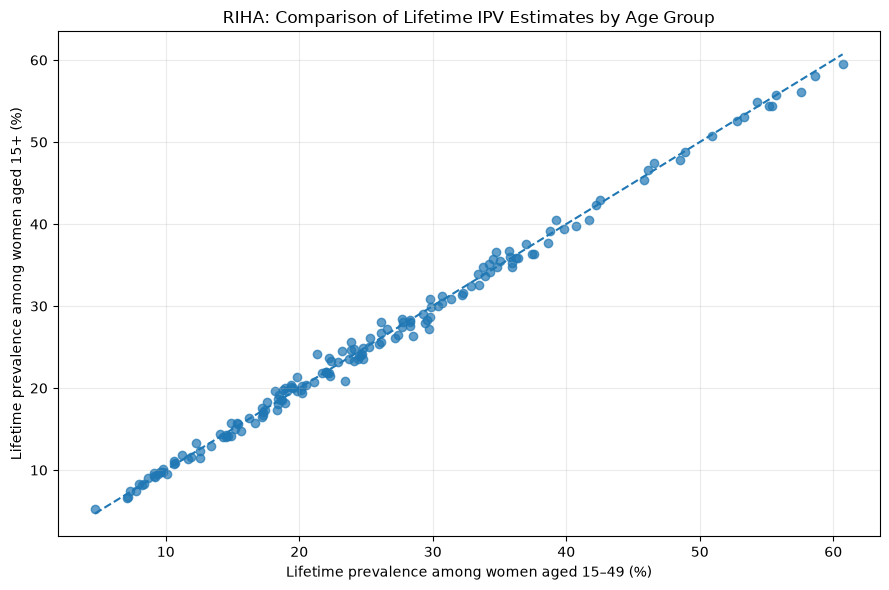

In [1936]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    comparison["Value_15_49"],
    comparison["Value_15_plus"],
    alpha=0.7
)
min_value = min(
    comparison["Value_15_49"].min(),
    comparison["Value_15_plus"].min()
)
max_value = max(
    comparison["Value_15_49"].max(),
    comparison["Value_15_plus"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Lifetime prevalence among women aged 15–49 (%)")
plt.ylabel("Lifetime prevalence among women aged 15+ (%)")
plt.title("RIHA: Comparison of Lifetime IPV Estimates by Age Group")
plt.grid(alpha=0.25)
plt.tight_layout()
from pathlib import Path

output_folder = Path(r"D:\Rihaa\outputs\figures")
output_folder.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_folder / "age_group_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Lifetime IPV prevalence by region (women aged 15–49):


,count,mean,median,min,max
Region,,,,,
Sub-Saharan Africa,40,31.40,31.45,8.2,55.2
East Asia & Pacific,29,29.26,23.90,7.1,60.7
North America,2,26.85,26.85,24.1,29.6
Middle East & North Africa,10,25.95,22.30,9.6,50.9
South Asia,6,25.67,21.85,14.3,48.9
Latin America & Caribbean,28,24.51,23.55,8.4,52.8
Europe & Central Asia,47,18.90,18.30,4.7,42.2


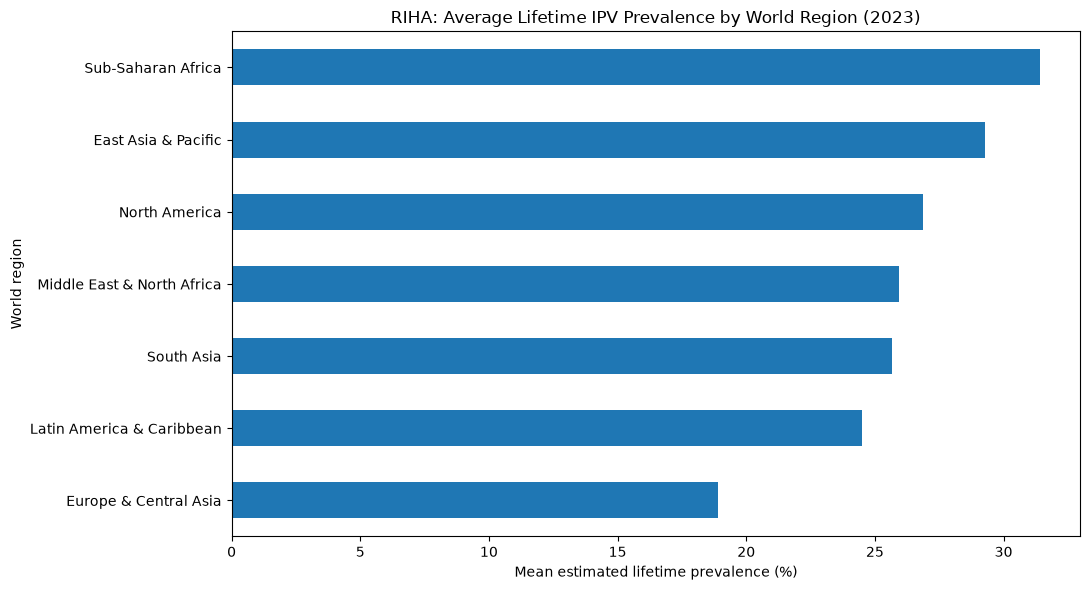

In [1937]:
import pandas as pd
import matplotlib.pyplot as plt
metadata_path = Path(r"D:\Rihaa\data\raw\Gender_StatsCountry.csv")
metadata = pd.read_csv(metadata_path, low_memory=False)
regional_data = indicator_15_49.merge(
    metadata[["Country Code", "Region"]],
    on="Country Code",
    how="left"
)
regional_data = regional_data.dropna(subset=["Region"])
region_summary = (
    regional_data.groupby("Region")["Value"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
    .sort_values("mean", ascending=False)
)

print("Lifetime IPV prevalence by region (women aged 15–49):")
display(region_summary)
plt.figure(figsize=(11, 6))

region_summary["mean"].sort_values().plot(kind="barh")

plt.xlabel("Mean estimated lifetime prevalence (%)")
plt.ylabel("World region")
plt.title("RIHA: Average Lifetime IPV Prevalence by World Region (2023)")
plt.tight_layout()

plt.savefig(
    output_folder / "regional_prevalence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [1938]:
highest_region=region_summary["mean"].idxmax()
lowest_region=region_summary["mean"].idxmin()
print("Highest average prevalence region:",highest_region)
print("Mean prevalence:",region_summary.loc[highest_region,"mean"],"%")
print("\nLowest average prevalence region:",lowest_region)
print("Mean prevalence:",region_summary.loc[lowest_region,"mean"],"%")
print("\nFull regional summary:")
display(region_summary)

Highest average prevalence region: Sub-Saharan Africa
Mean prevalence: 31.4 %

Lowest average prevalence region: Europe & Central Asia
Mean prevalence: 18.9 %

Full regional summary:


,count,mean,median,min,max
Region,,,,,
Sub-Saharan Africa,40,31.40,31.45,8.2,55.2
East Asia & Pacific,29,29.26,23.90,7.1,60.7
North America,2,26.85,26.85,24.1,29.6
Middle East & North Africa,10,25.95,22.30,9.6,50.9
South Asia,6,25.67,21.85,14.3,48.9
Latin America & Caribbean,28,24.51,23.55,8.4,52.8
Europe & Central Asia,47,18.90,18.30,4.7,42.2


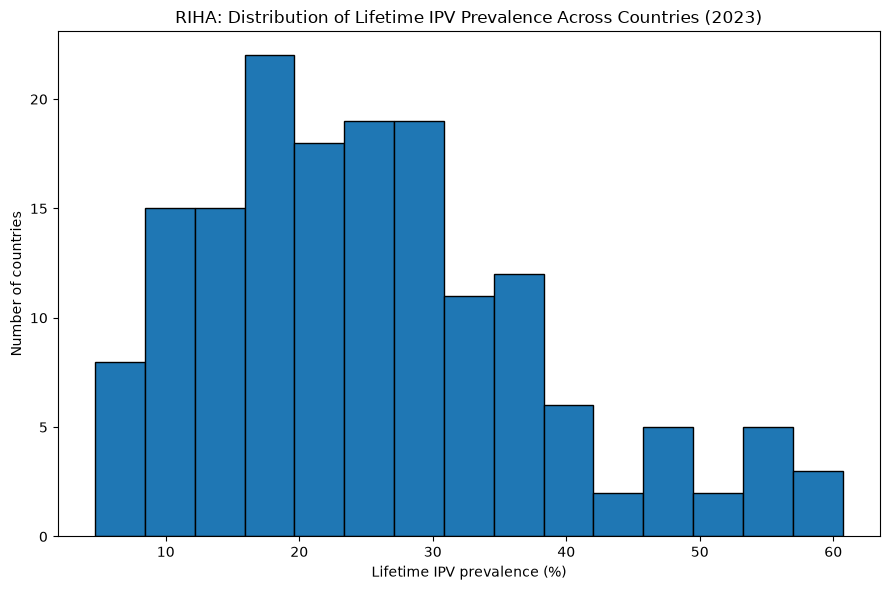

In [1939]:
plt.figure(figsize=(9,6))
plt.hist(indicator_15_49["Value"],bins=15,edgecolor="black")
plt.xlabel("Lifetime IPV prevalence (%)")
plt.ylabel("Number of countries")
plt.title("RIHA: Distribution of Lifetime IPV Prevalence Across Countries (2023)")
plt.tight_layout()
plt.savefig(output_folder/"prevalence_distribution.png",dpi=300,bbox_inches="tight")
plt.show()

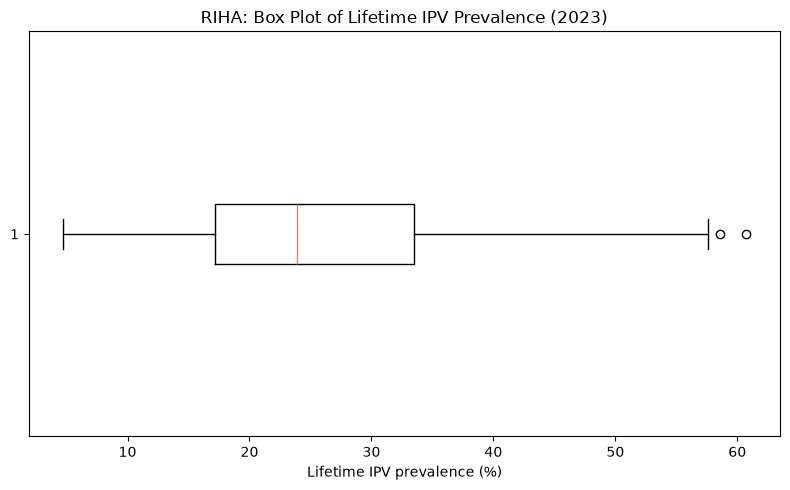

In [1940]:
plt.figure(figsize=(8,5))
plt.boxplot(indicator_15_49["Value"],orientation="horizontal")
plt.xlabel("Lifetime IPV prevalence (%)")
plt.title("RIHA: Box Plot of Lifetime IPV Prevalence (2023)")
plt.tight_layout()
plt.savefig(output_folder/"prevalence_boxplot.png",dpi=300,bbox_inches="tight")
plt.show()

In [1941]:
Q1=indicator_15_49["Value"].quantile(0.25)
Q3=indicator_15_49["Value"].quantile(0.75)
IQR=Q3-Q1
lower_bound=Q1-1.5*IQR
upper_bound=Q3+1.5*IQR
outliers=indicator_15_49[(indicator_15_49["Value"]<lower_bound)|(indicator_15_49["Value"]>upper_bound)]
print("Q1:",Q1)
print("Q3:",Q3)
print("IQR:",IQR)
print("Lower bound:",lower_bound)
print("Upper bound:",upper_bound)
print("Number of potential outliers:",len(outliers))
display(outliers[["Country Name","Country Code","Value"]])

Q1: 17.2
Q3: 33.475
IQR: 16.275000000000002
Lower bound: -7.212500000000002
Upper bound: 57.8875
Number of potential outliers: 2


,Country Name,Country Code,Value
65,Fiji,FJI,60.7
147,Solomon Islands,SLB,58.6


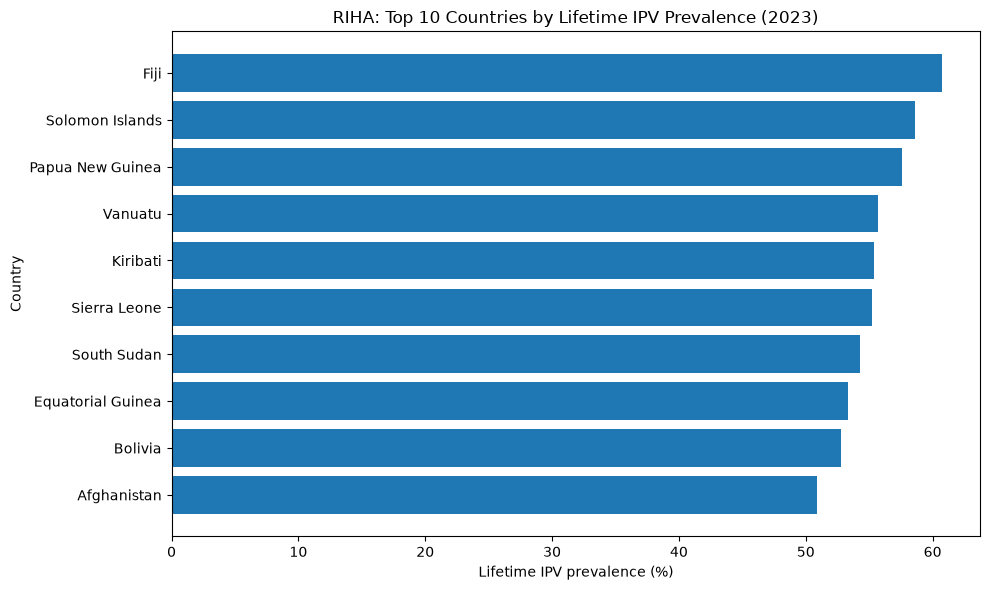

In [1942]:
top10=indicator_15_49.nlargest(10,"Value").sort_values("Value")
plt.figure(figsize=(10,6))
plt.barh(top10["Country Name"],top10["Value"])
plt.xlabel("Lifetime IPV prevalence (%)")
plt.ylabel("Country")
plt.title("RIHA: Top 10 Countries by Lifetime IPV Prevalence (2023)")
plt.tight_layout()
plt.savefig(output_folder/"top10_countries_prevalence.png",dpi=300,bbox_inches="tight")
plt.show()

In [1943]:
cleaned_data=indicator_15_49[["Country Name","Country Code","Year","Value","Indicator Code","Indicator Name","Disaggregation"]].copy()
cleaned_data=cleaned_data.drop_duplicates()
cleaned_data=cleaned_data.dropna(subset=["Country Name","Country Code","Year","Value"])
cleaned_data["Year"]=cleaned_data["Year"].astype(int)
cleaned_data["Value"]=cleaned_data["Value"].astype(float)
cleaned_data=cleaned_data.sort_values("Value",ascending=False)
processed_folder=Path(r"D:\Rihaa\data\processed")
processed_folder.mkdir(parents=True,exist_ok=True)
cleaned_data.to_csv(processed_folder/"riha_lifetime_ipv_15_49_2023.csv",index=False)
print("Saved:",processed_folder/"riha_lifetime_ipv_15_49_2023.csv")
print("Final shape:",cleaned_data.shape)
display(cleaned_data.head())

Saved: D:\Rihaa\data\processed\riha_lifetime_ipv_15_49_2023.csv
Final shape: (162, 7)


,Country Name,Country Code,Year,Value,Indicator Code,Indicator Name,Disaggregation
65,Fiji,FJI,2023,60.7,SG.VAW.1549.LT.ME.ZS,Proportion of women who have ever experienced ...,"female, Modeled, 15-49"
147,Solomon Islands,SLB,2023,58.6,SG.VAW.1549.LT.ME.ZS,Proportion of women who have ever experienced ...,"female, Modeled, 15-49"
131,Papua New Guinea,PNG,2023,57.6,SG.VAW.1549.LT.ME.ZS,Proportion of women who have ever experienced ...,"female, Modeled, 15-49"
173,Vanuatu,VUT,2023,55.7,SG.VAW.1549.LT.ME.ZS,Proportion of women who have ever experienced ...,"female, Modeled, 15-49"
93,Kiribati,KIR,2023,55.4,SG.VAW.1549.LT.ME.ZS,Proportion of women who have ever experienced ...,"female, Modeled, 15-49"


In [1944]:
saved_data=pd.read_csv(processed_folder/"riha_lifetime_ipv_15_49_2023.csv")
print("Dataset shape:",saved_data.shape)
print("Missing values:",saved_data.isnull().sum().sum())
print("Duplicate rows:",saved_data.duplicated().sum())
print("Unique countries:",saved_data["Country Code"].nunique())
print("Year range:",saved_data["Year"].min(),"-",saved_data["Year"].max())

Dataset shape: (162, 7)
Missing values: 0
Duplicate rows: 0
Unique countries: 162
Year range: 2023 - 2023


In [1945]:
original_2023=df_1549[df_1549["Year"]==2023]
print("Original 2023 records:",len(original_2023))
print("Original missing values:",original_2023["Value"].isnull().sum())
print("Cleaned country records:",len(saved_data))
print("Countries in cleaned dataset:",saved_data["Country Code"].nunique())
print("Countries with estimates:",saved_data["Value"].notnull().sum())
print("Missing country estimates must not be treated as zero.")

Original 2023 records: 548
Original missing values: 0
Cleaned country records: 162
Countries in cleaned dataset: 162
Countries with estimates: 162
Missing country estimates must not be treated as zero.


In [1946]:
top10=saved_data.nlargest(10,"Value")[["Country Name","Value"]]
bottom10=saved_data.nsmallest(10,"Value")[["Country Name","Value"]]
print("Top 10 countries:")
display(top10)
print("Bottom 10 countries:")
display(bottom10)
top10.to_csv(output_folder/"top10_countries.csv",index=False)
bottom10.to_csv(output_folder/"bottom10_countries.csv",index=False)

Top 10 countries:


,Country Name,Value
0,Fiji,60.7
1,Solomon Islands,58.6
2,Papua New Guinea,57.6
3,Vanuatu,55.7
4,Kiribati,55.4
5,Sierra Leone,55.2
6,South Sudan,54.3
7,Equatorial Guinea,53.3
8,Bolivia,52.8
9,Afghanistan,50.9


Bottom 10 countries:


,Country Name,Value
161,Kosovo,4.7
160,Singapore,7.1
159,Philippines,7.2
158,Georgia,7.3
157,Bulgaria,7.8
156,Montenegro,8.0
155,Comoros,8.2
154,Cuba,8.4
153,Armenia,8.7
151,Serbia,9.1


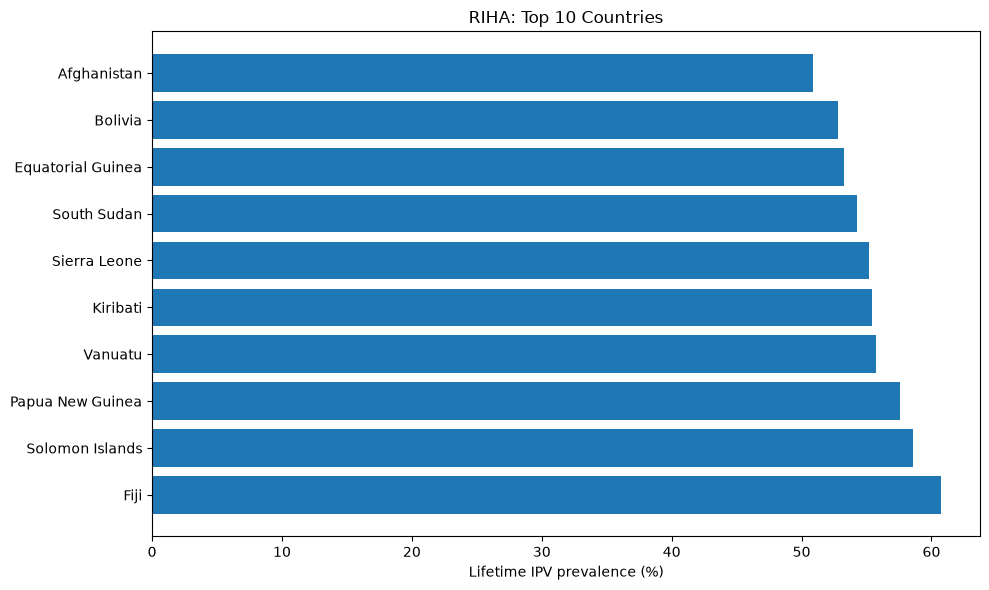

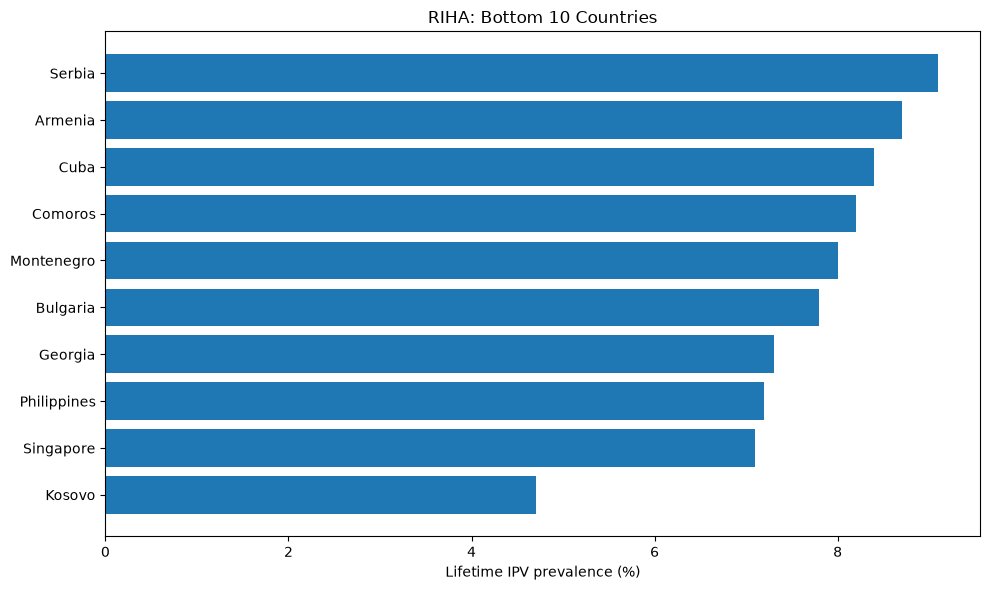

In [1947]:
plt.figure(figsize=(10,6))
plt.barh(top10["Country Name"],top10["Value"])
plt.xlabel("Lifetime IPV prevalence (%)")
plt.title("RIHA: Top 10 Countries")
plt.tight_layout()
plt.savefig(output_folder/"top10_countries_chart.png",dpi=300,bbox_inches="tight")
plt.show()

plt.figure(figsize=(10,6))
plt.barh(bottom10["Country Name"],bottom10["Value"])
plt.xlabel("Lifetime IPV prevalence (%)")
plt.title("RIHA: Bottom 10 Countries")
plt.tight_layout()
plt.savefig(output_folder/"bottom10_countries_chart.png",dpi=300,bbox_inches="tight")
plt.show()

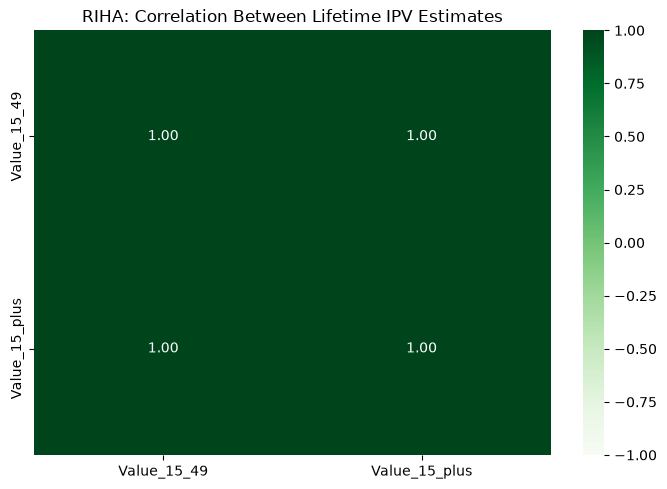

In [1948]:
plt.figure(figsize=(7,5))
correlation=comparison[["Value_15_49","Value_15_plus"]].corr()
sns.heatmap(correlation,annot=True,cmap="Greens",vmin=-1,vmax=1,fmt=".2f")
plt.title("RIHA: Correlation Between Lifetime IPV Estimates")
plt.tight_layout()
plt.savefig(output_folder/"indicator_correlation_heatmap.png",dpi=300,bbox_inches="tight")
plt.show()

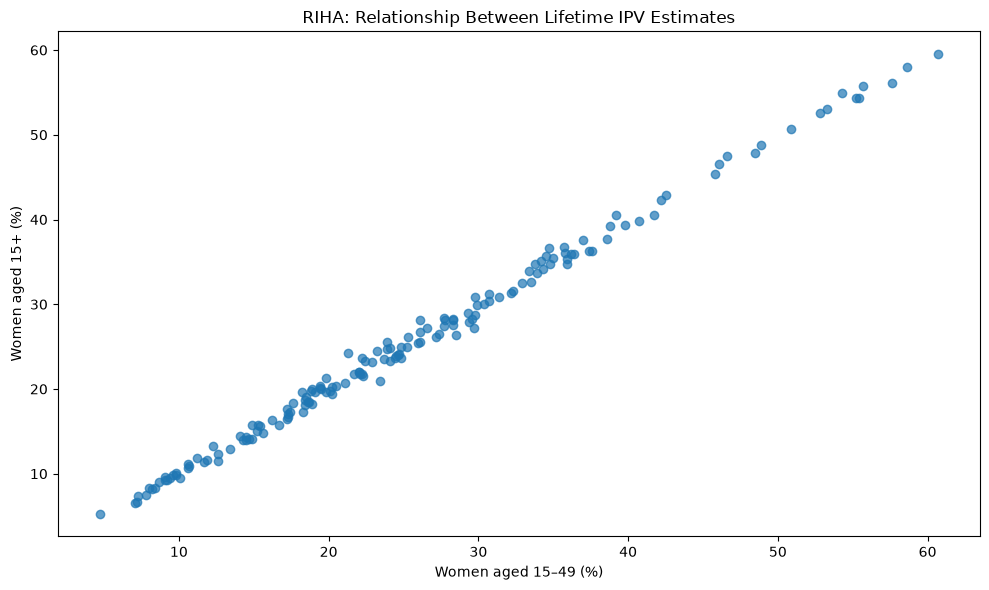

Correlation: 0.998


In [1949]:
plt.figure(figsize=(10,6))
plt.scatter(comparison["Value_15_49"],comparison["Value_15_plus"],alpha=0.7)
plt.xlabel("Women aged 15–49 (%)")
plt.ylabel("Women aged 15+ (%)")
plt.title("RIHA: Relationship Between Lifetime IPV Estimates")
plt.tight_layout()
plt.savefig(output_folder/"indicator_relationship.png",dpi=300,bbox_inches="tight")
plt.show()
print("Correlation:",round(comparison["Value_15_49"].corr(comparison["Value_15_plus"]),3))

In [1950]:
summary=pd.DataFrame({
    "Metric":["Number of countries","Mean prevalence (%)","Median prevalence (%)","Minimum prevalence (%)","Maximum prevalence (%)","Standard deviation"],
    "Value":[
        saved_data["Country Code"].nunique(),
        round(saved_data["Value"].mean(),2),
        round(saved_data["Value"].median(),2),
        round(saved_data["Value"].min(),2),
        round(saved_data["Value"].max(),2),
        round(saved_data["Value"].std(),2)
    ]
})
display(summary)
summary.to_csv(output_folder/"riha_summary_statistics.csv",index=False)

,Metric,Value
0,Number of countries,162.00
1,Mean prevalence (%),25.59
2,Median prevalence (%),23.90
3,Minimum prevalence (%),4.70
4,Maximum prevalence (%),60.70
5,Standard deviation,12.50


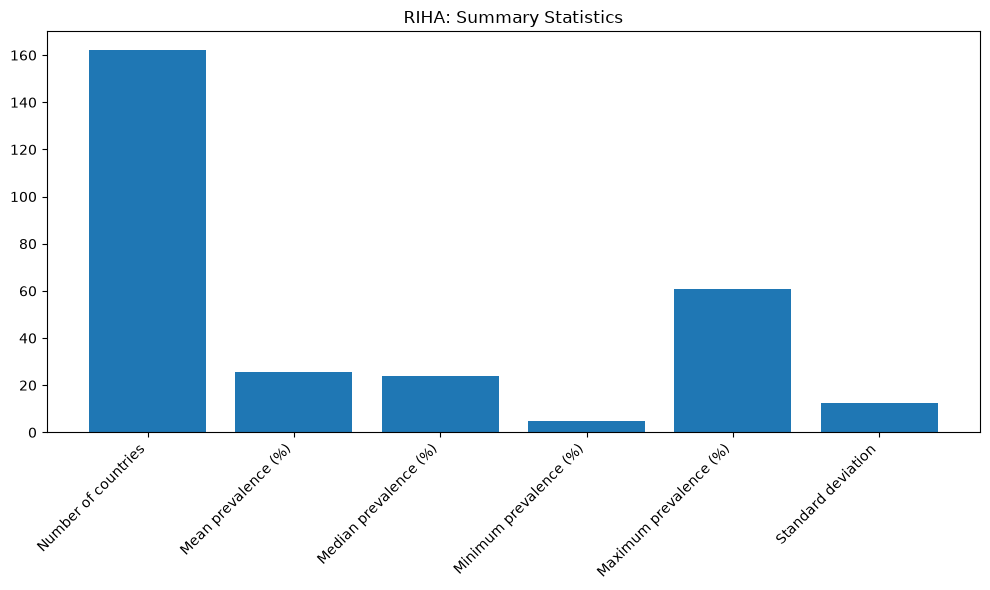

In [1951]:
plt.figure(figsize=(10,6))
plt.bar(summary["Metric"],summary["Value"])
plt.xticks(rotation=45,ha="right")
plt.title("RIHA: Summary Statistics")
plt.tight_layout()
plt.savefig(output_folder/"summary_statistics_chart.png",dpi=300,bbox_inches="tight")
plt.show()

In [1952]:
print("RIHA Analysis Summary")
print("="*40)
print("Total countries analyzed:",saved_data["Country Code"].nunique())
print("Average prevalence:",round(saved_data["Value"].mean(),2),"%")
print("Median prevalence:",round(saved_data["Value"].median(),2),"%")
print("Highest prevalence:",saved_data.loc[saved_data["Value"].idxmax(),"Country Name"],"-",saved_data["Value"].max(),"%")
print("Lowest prevalence:",saved_data.loc[saved_data["Value"].idxmin(),"Country Name"],"-",saved_data["Value"].min(),"%")
print("Figures saved:",len(list(output_folder.glob("*.png"))))
print("Processed dataset saved:",(processed_folder/"riha_lifetime_ipv_15_49_2023.csv").exists())

RIHA Analysis Summary
Total countries analyzed: 162
Average prevalence: 25.59 %
Median prevalence: 23.9 %
Highest prevalence: Fiji - 60.7 %
Lowest prevalence: Kosovo - 4.7 %
Figures saved: 24
Processed dataset saved: True


# Key Findings

1. The analysis examines modeled estimates of lifetime intimate partner violence among women aged 15–49 across 162 countries in 2023.
2. The mean estimated prevalence across the included countries is approximately 25.59%, while the median is 23.90%.
3. Estimates vary considerably between countries, with values ranging from 4.7% to 60.7%.
4. Comparing estimates for women aged 15–49 with those for women aged 15 and older shows that the two indicators are generally similar, although some countries have larger differences.
5. Regional averages show variation across world regions. These are unweighted averages of available country estimates, not population-weighted regional prevalence rates.

# Limitations

1. The dataset contains modeled prevalence estimates, not counts of reported incidents or police cases.
2. Missing estimates do not mean that no violence occurred; they indicate that an estimate was unavailable in the selected data.
3. The analysis covers intimate partner violence and does not represent every form of violence against women.
4. The results describe estimates for 2023 and should not be interpreted as current real-time conditions.
5. Regional averages are calculated from available country estimates without population weighting.
6. Differences between indicators may reflect differences in age-group definitions and estimation methods. The indicators should not be treated as interchangeable.
7. The analysis identifies patterns and associations but does not establish the causes of violence.

# Recommendations

1. Improve the availability and consistency of reliable, ethically collected data on violence against women.
2. Support prevention, education, accessible services, and survivor-centred assistance.
3. Use country and regional estimates to identify areas for further investigation, while considering differences in data coverage and methodology.
4. Avoid interpreting low estimates as proof that a country is completely safe.
5. Update the analysis when newer, comparable data become available.

# Conclusion

RIHA — Global Women's Safety & Equality Analytics uses real-world data analysis to examine modeled estimates of lifetime intimate partner violence among women across countries. Data cleaning, descriptive statistics, country comparisons, and visualizations help reveal variation in the available estimates. The project also highlights important data limitations, including missing estimates and differences between indicators. These results can support awareness and further research, but they should not be interpreted as counts of reported crimes or as a complete measure of women's safety. Reliable data, responsible interpretation, prevention, and survivor-centred support are essential to advancing women's safety and equality.

# Methodology

## 1. Data Collection
The project uses World Bank Gender Statistics data containing country-level estimates related to violence against women. The primary indicator measures lifetime intimate partner violence among ever-partnered women aged 15–49 for 2023.

## 2. Data Exploration
Pandas was used to inspect dataset dimensions, column names, data types, missing values, duplicate records, and descriptive statistics.

## 3. Data Cleaning
The analysis selected the relevant indicator and year, excluded regional aggregates from the country-level analysis, checked missing values and duplicates, and converted columns to appropriate data types. Missing estimates were not replaced with zero.

## 4. Exploratory Data Analysis
Pandas and NumPy supported statistical analysis. Matplotlib and Seaborn were used to create visualizations, including histograms, box plots, bar charts, scatter plots, and a correlation heatmap.

## 5. Comparative Analysis
Lifetime prevalence estimates for women aged 15–49 were compared with estimates for women aged 15 and older. The indicators were analyzed separately because their age-group definitions differ.

## 6. Interpretation
Results were interpreted using descriptive statistics and visual patterns. Potential outliers were investigated rather than automatically removed, because unusually high estimates may represent meaningful differences between countries.

## 7. Data Limitations
The analysis uses modeled prevalence estimates rather than reported incident counts. Findings depend on data availability and indicator definitions and do not represent every form of violence against women.

In [1953]:
from IPython.display import display, Markdown

display(Markdown("""
# Data Sources and Tools

## Data Source
- **Source:** World Bank Gender Statistics
- **Website:** https://genderdata.worldbank.org/
- **Dataset:** Gender Statistics and the indicator on lifetime intimate partner violence among ever-partnered women aged 15-49.
- **Analysis year:** 2023

## Python Libraries
- **Pandas:** Data loading, cleaning, filtering, and analysis.
- **NumPy:** Numerical operations.
- **Matplotlib:** Charts and visualizations.
- **Seaborn:** Statistical visualizations and correlation heatmaps.
- **Pathlib:** File and folder management.

## Project Details
- **Project Name:** RIHA - Global Women's Safety & Equality Analytics
- **Tagline:** Freedom Without Fear.
- **Project Type:** Real-world dataset analysis and exploratory data analysis (EDA).
"""))


# Data Sources and Tools

## Data Source
- **Source:** World Bank Gender Statistics
- **Website:** https://genderdata.worldbank.org/
- **Dataset:** Gender Statistics and the indicator on lifetime intimate partner violence among ever-partnered women aged 15-49.
- **Analysis year:** 2023

## Python Libraries
- **Pandas:** Data loading, cleaning, filtering, and analysis.
- **NumPy:** Numerical operations.
- **Matplotlib:** Charts and visualizations.
- **Seaborn:** Statistical visualizations and correlation heatmaps.
- **Pathlib:** File and folder management.

## Project Details
- **Project Name:** RIHA - Global Women's Safety & Equality Analytics
- **Tagline:** Freedom Without Fear.
- **Project Type:** Real-world dataset analysis and exploratory data analysis (EDA).


In [1954]:
findings = pd.DataFrame({
    "Finding": [
        "Countries analyzed",
        "Mean lifetime IPV prevalence",
        "Median lifetime IPV prevalence",
        "Minimum lifetime IPV prevalence",
        "Maximum lifetime IPV prevalence",
        "Highest estimate country",
        "Lowest estimate country"
    ],
    "Result": [
        saved_data["Country Code"].nunique(),
        f'{saved_data["Value"].mean():.2f}%',
        f'{saved_data["Value"].median():.2f}%',
        f'{saved_data["Value"].min():.2f}%',
        f'{saved_data["Value"].max():.2f}%',
        saved_data.loc[saved_data["Value"].idxmax(), "Country Name"],
        saved_data.loc[saved_data["Value"].idxmin(), "Country Name"]
    ]
})

display(findings)

findings.to_csv(
    output_folder / "riha_key_findings.csv",
    index=False
)

print("Key findings saved successfully.")

,Finding,Result
0,Countries analyzed,162
1,Mean lifetime IPV prevalence,25.59%
2,Median lifetime IPV prevalence,23.90%
3,Minimum lifetime IPV prevalence,4.70%
4,Maximum lifetime IPV prevalence,60.70%
5,Highest estimate country,Fiji
6,Lowest estimate country,Kosovo


Key findings saved successfully.


In [1955]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "data/processed/riha_lifetime_ipv_15_49_2023.csv"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (162, 7)


,Country Name,Country Code,Year,Value,Indicator Code,Indicator Name,Disaggregation
0,Fiji,FJI,2023,60.7,SG.VAW.1549.LT.ME.ZS,Proportion of women who have ever experienced ...,"female, Modeled, 15-49"
1,Solomon Islands,SLB,2023,58.6,SG.VAW.1549.LT.ME.ZS,Proportion of women who have ever experienced ...,"female, Modeled, 15-49"
2,Papua New Guinea,PNG,2023,57.6,SG.VAW.1549.LT.ME.ZS,Proportion of women who have ever experienced ...,"female, Modeled, 15-49"
3,Vanuatu,VUT,2023,55.7,SG.VAW.1549.LT.ME.ZS,Proportion of women who have ever experienced ...,"female, Modeled, 15-49"
4,Kiribati,KIR,2023,55.4,SG.VAW.1549.LT.ME.ZS,Proportion of women who have ever experienced ...,"female, Modeled, 15-49"


In [1956]:
# DATA QUALITY ASSESSMENT

print("========== DATA QUALITY REPORT ==========")

# 1. Dataset dimensions
print("\n1. Dataset Dimensions")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# 2. Data types
print("\n2. Column Data Types")
print(df.dtypes)

# 3. Missing values
print("\n3. Missing Values")
print(df.isnull().sum())

# 4. Duplicate records
print("\n4. Duplicate Records")
print(df.duplicated().sum())

# 5. Unique countries
print("\n5. Unique Countries")
print(df["Country Code"].nunique())

# 6. Year verification
print("\n6. Available Years")
print(df["Year"].unique())

# 7. Value range
print("\n7. Prevalence Range")
print("Minimum:", df["Value"].min())
print("Maximum:", df["Value"].max())

# 8. Duplicate country codes
print("\n8. Duplicate Country Codes")
print(df["Country Code"].duplicated().sum())

print("\n========== ASSESSMENT COMPLETED ==========")

========== DATA QUALITY REPORT ==========

1. Dataset Dimensions
Rows: 162
Columns: 7

2. Column Data Types
Country Name          str
Country Code          str
Year                int64
Value             float64
Indicator Code        str
Indicator Name        str
Disaggregation        str
dtype: object

3. Missing Values
Country Name      0
Country Code      0
Year              0
Value             0
Indicator Code    0
Indicator Name    0
Disaggregation    0
dtype: int64

4. Duplicate Records
0

5. Unique Countries
162

6. Available Years
[2023]

7. Prevalence Range
Minimum: 4.7
Maximum: 60.7

8. Duplicate Country Codes
0

========== ASSESSMENT COMPLETED ==========


In [1957]:
print("========== FINAL VALIDATION ==========")

# Check invalid prevalence values
invalid_values = df[
    (df["Value"] < 0) | (df["Value"] > 100)
]

print("Invalid prevalence values:", len(invalid_values))

# Check years
print("Available years:", df["Year"].unique())

# Check indicators
print("Unique indicators:", df["Indicator Code"].nunique())

# Check disaggregation
print("Disaggregation categories:")
print(df["Disaggregation"].unique())

# Check country records
print("Country records:", df["Country Name"].nunique())

print("\n========== VALIDATION COMPLETED ==========")

========== FINAL VALIDATION ==========
Invalid prevalence values: 0
Available years: [2023]
Unique indicators: 1
Disaggregation categories:
<ArrowStringArray>
['female, Modeled, 15-49']
Length: 1, dtype: str
Country records: 162

========== VALIDATION COMPLETED ==========


### Data Quality Assessment

The RIHA project dataset was evaluated to determine its suitability for statistical analysis and research.

The dataset contains 162 country-level observations and seven columns, including country name, country code, year, prevalence value, indicator code, indicator name, and disaggregation.

The validation process identified no missing values, duplicate rows, or duplicate country codes. All prevalence values were within the valid range of 0–100%. The dataset contained observations for a single reporting year, 2023, and maintained a consistent population definition of modeled estimates for ever-partnered women aged 15–49.

All numerical and categorical columns were stored using appropriate data types.

Based on these checks, the dataset was considered suitable for the planned exploratory data analysis. No data cleaning or record removal was required for this dataset.


In [1958]:
# PHASE 2.1: DESCRIPTIVE STATISTICS

print("========== DESCRIPTIVE STATISTICS ==========")

print("\nStatistical Summary:")
print(df["Value"].describe())

print("\nMean Prevalence:", round(df["Value"].mean(), 2), "%")
print("Median Prevalence:", round(df["Value"].median(), 2), "%")
print("Standard Deviation:", round(df["Value"].std(), 2), "%")

print("\nLowest Prevalence:")
print(df.loc[df["Value"].idxmin(), ["Country Name", "Value"]])

print("\nHighest Prevalence:")
print(df.loc[df["Value"].idxmax(), ["Country Name", "Value"]])

========== DESCRIPTIVE STATISTICS ==========

Statistical Summary:
count    162.000000
mean      25.592593
std       12.495522
min        4.700000
25%       17.200000
50%       23.900000
75%       33.475000
max       60.700000
Name: Value, dtype: float64

Mean Prevalence: 25.59 %
Median Prevalence: 23.9 %
Standard Deviation: 12.5 %

Lowest Prevalence:
Country Name    Kosovo
Value              4.7
Name: 161, dtype: object

Highest Prevalence:
Country Name    Fiji
Value           60.7
Name: 0, dtype: object


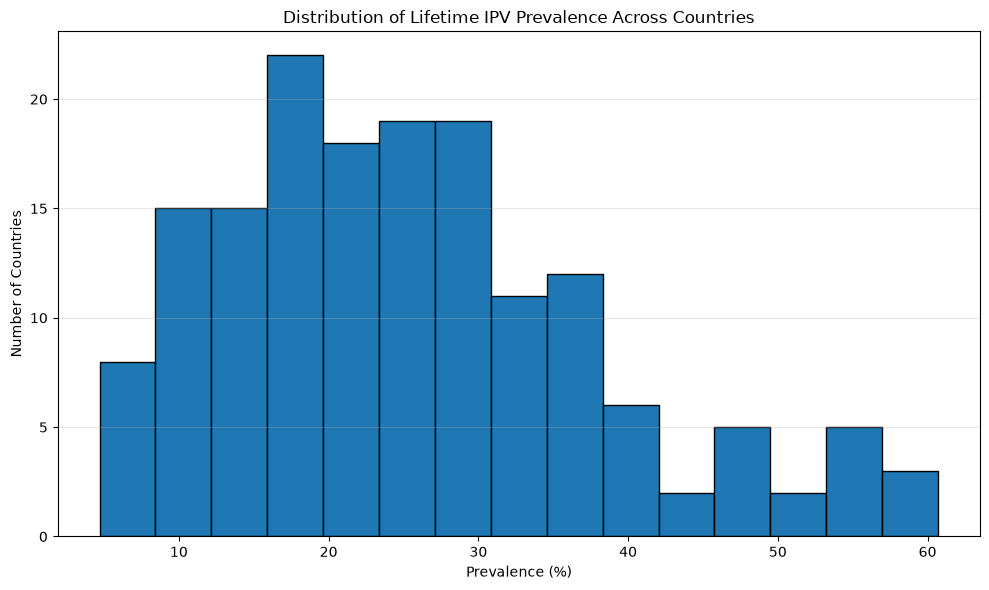

In [1959]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(df["Value"], bins=15, edgecolor="black")

plt.title("Distribution of Lifetime IPV Prevalence Across Countries")
plt.xlabel("Prevalence (%)")
plt.ylabel("Number of Countries")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig("outputs/figures/01_prevalence_distribution.png", dpi=300)
plt.show()

The histogram illustrates the distribution of lifetime intimate partner violence (IPV) prevalence across 162 countries in 2023. Most countries have prevalence estimates concentrated between approximately 15% and 30%. The distribution is positively skewed, indicating that a smaller group of countries has substantially higher prevalence estimates. Several countries fall above 40%, highlighting considerable variation in IPV prevalence across countries.


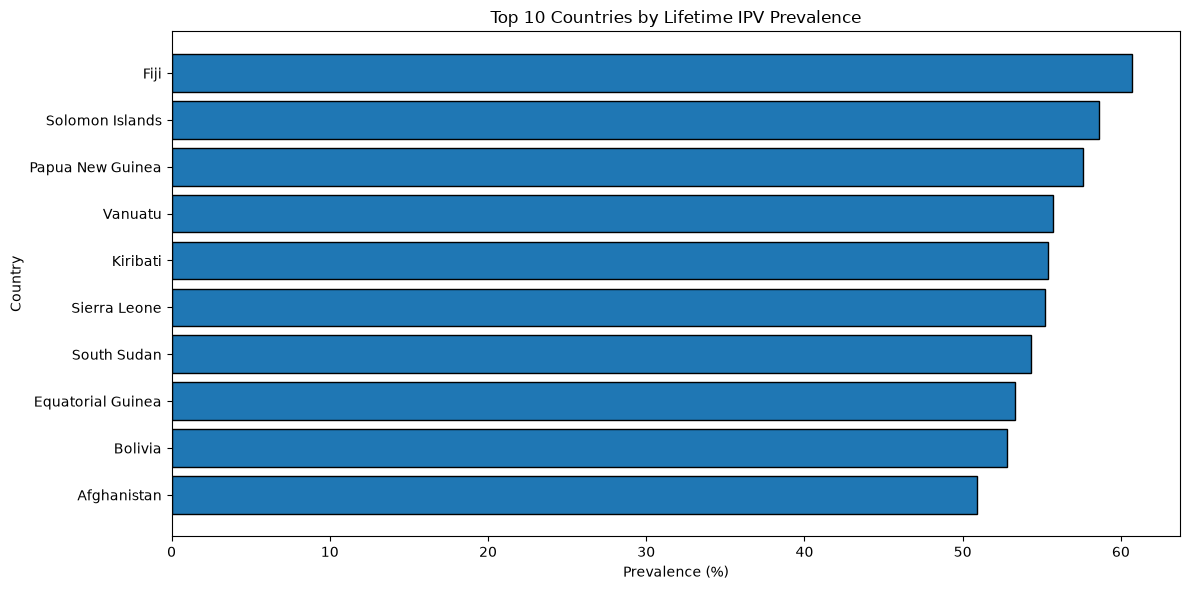

In [1960]:
# PHASE 2.2: TOP 10 COUNTRIES

top_10 = df.nlargest(10, "Value")

plt.figure(figsize=(12, 6))

plt.barh(top_10["Country Name"], top_10["Value"],
         edgecolor="black")

plt.title("Top 10 Countries by Lifetime IPV Prevalence")
plt.xlabel("Prevalence (%)")
plt.ylabel("Country")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig("outputs/figures/02_top_10_countries.png", dpi=300)
plt.show()

In [1961]:
print("TOP 10 COUNTRIES BY IPV PREVALENCE")
print(top_10[["Country Name", "Value"]].to_string(index=False))

TOP 10 COUNTRIES BY IPV PREVALENCE
     Country Name  Value
             Fiji   60.7
  Solomon Islands   58.6
 Papua New Guinea   57.6
          Vanuatu   55.7
         Kiribati   55.4
     Sierra Leone   55.2
      South Sudan   54.3
Equatorial Guinea   53.3
          Bolivia   52.8
      Afghanistan   50.9


The country ranking identifies Fiji as having the highest lifetime IPV prevalence estimate at 60.7%, followed by the Solomon Islands at 58.6% and Papua New Guinea at 57.6%. All ten countries have estimates above 50%. This highlights substantial variation in lifetime IPV prevalence across countries and identifies locations that warrant further investigation. These figures are modeled estimates and should not be interpreted as proof of the causes of the differences.


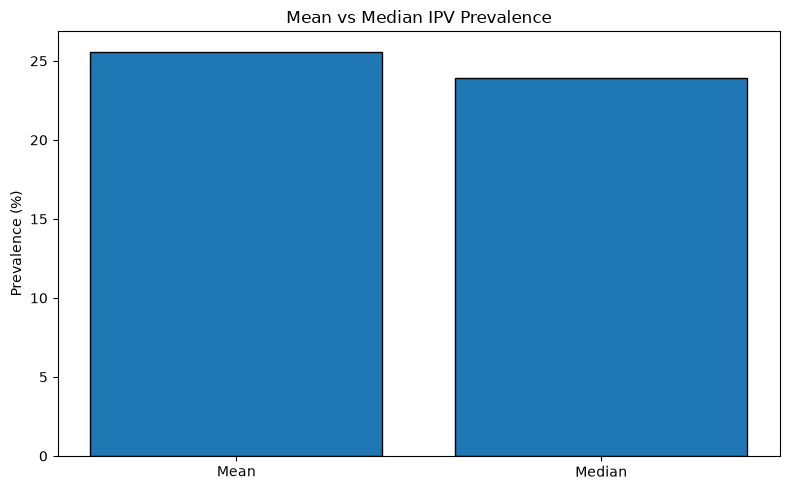

In [1962]:
# PHASE 2.3: MEAN VS MEDIAN

mean_value = df["Value"].mean()
median_value = df["Value"].median()

plt.figure(figsize=(8, 5))

plt.bar(
    ["Mean", "Median"],
    [mean_value, median_value],
    edgecolor="black"
)

plt.title("Mean vs Median IPV Prevalence")
plt.ylabel("Prevalence (%)")

plt.tight_layout()

plt.savefig("outputs/figures/03_mean_vs_median.png", dpi=300)
plt.show()

The mean lifetime IPV prevalence across the 162 countries is 25.59%, while the median is 23.90%. The mean is higher than the median by 1.69 percentage points, suggesting that relatively high prevalence estimates in some countries pull the average upward. This is consistent with the positive skew observed in the histogram.


In [1963]:

bottom_10 = df.nsmallest(10, "Value")

print("BOTTOM 10 COUNTRIES BY IPV PREVALENCE")
print(bottom_10[["Country Name", "Value"]].to_string(index=False))

BOTTOM 10 COUNTRIES BY IPV PREVALENCE
Country Name  Value
      Kosovo    4.7
   Singapore    7.1
 Philippines    7.2
     Georgia    7.3
    Bulgaria    7.8
  Montenegro    8.0
     Comoros    8.2
        Cuba    8.4
     Armenia    8.7
      Serbia    9.1


The analysis identifies Kosovo as having the lowest lifetime IPV prevalence estimate at 4.7%, followed by Singapore at 7.1% and the Philippines at 7.2%. All ten countries have estimates below 10%. These results highlight differences in modeled prevalence estimates across countries. However, lower estimates should not automatically be interpreted as evidence of lower actual violence, because reporting practices, data availability, and estimation methods may differ.


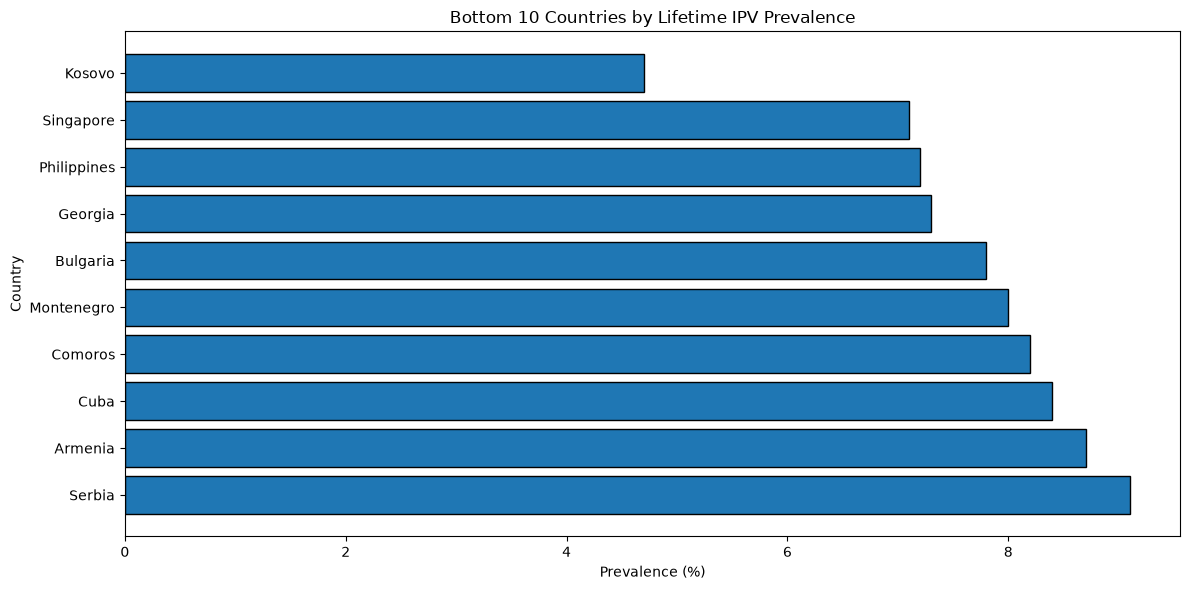

In [1964]:

plt.figure(figsize=(12, 6))

plt.barh(
    bottom_10["Country Name"],
    bottom_10["Value"],
    edgecolor="black"
)

plt.title("Bottom 10 Countries by Lifetime IPV Prevalence")
plt.xlabel("Prevalence (%)")
plt.ylabel("Country")

plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig("outputs/figures/04_bottom_10_countries.png", dpi=300)
plt.show()

In [1965]:


def classify_prevalence(value):
    if value < 15:
        return "Low"
    elif value < 30:
        return "Moderate"
    else:
        return "High"

df["Prevalence Category"] = df["Value"].apply(classify_prevalence)

category_counts = df["Prevalence Category"].value_counts()

print("COUNTRY DISTRIBUTION BY PREVALENCE CATEGORY")
print(category_counts)

print("\nPercentage Distribution:")
print((category_counts / len(df) * 100).round(2))

COUNTRY DISTRIBUTION BY PREVALENCE CATEGORY
Prevalence Category
Moderate    79
High        49
Low         34
Name: count, dtype: int64

Percentage Distribution:
Prevalence Category
Moderate    48.77
High        30.25
Low         20.99
Name: count, dtype: float64


The analysis classifies 162 countries into three categories based on lifetime IPV prevalence estimates. The moderate category (15% to below 30%) contains the largest number of countries, with 79 countries (48.77%). The high category (30% and above) includes 49 countries (30.25%), while the low category (below 15%) contains 34 countries (20.99%). These findings indicate that nearly one-third of the analysed countries have prevalence estimates of 30% or higher. The categories are analytical groupings created for this study and are not official risk classifications.


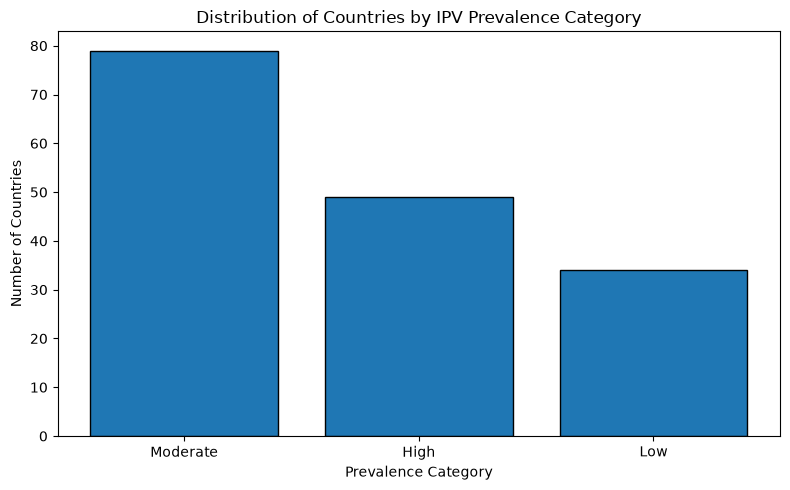

In [1966]:


plt.figure(figsize=(8, 5))

plt.bar(
    category_counts.index,
    category_counts.values,
    edgecolor="black"
)

plt.title("Distribution of Countries by IPV Prevalence Category")
plt.xlabel("Prevalence Category")
plt.ylabel("Number of Countries")

plt.tight_layout()

plt.savefig("outputs/figures/05_prevalence_categories.png", dpi=300)
plt.show()

In [1967]:

print("Available Columns:")
print(df.columns.tolist())

Available Columns:
['Country Name', 'Country Code', 'Year', 'Value', 'Indicator Code', 'Indicator Name', 'Disaggregation', 'Prevalence Category']


In [1968]:
import country_converter as coco

cc = coco.CountryConverter()

print("Country converter is ready!")


Country converter is ready!


In [1969]:
import pandas as pd
import requests

url = "https://api.worldbank.org/v2/country?format=json&per_page=400"

response = requests.get(url)
response.raise_for_status()

data = response.json()
wb_regions = pd.json_normalize(data[1])

wb_regions = wb_regions[["id", "name", "region.value"]]

wb_regions.columns = ["Country Code", "WB Country Name", "Region"]

print("World Bank regional data fetched successfully!")
print("\nFirst 10 records:")
print(wb_regions.head(10))

World Bank regional data fetched successfully!

First 10 records:
  Country Code              WB Country Name  \
0          ABW                        Aruba   
1          AFE  Africa Eastern and Southern   
2          AFG                  Afghanistan   
3          AFR                       Africa   
4          AFW   Africa Western and Central   
5          AGO                       Angola   
6          ALB                      Albania   
7          AND                      Andorra   
8          ARB                   Arab World   
9          ARE         United Arab Emirates   

                                              Region  
0                         Latin America & Caribbean   
1                                         Aggregates  
2  Middle East, North Africa, Afghanistan & Pakistan  
3                                         Aggregates  
4                                         Aggregates  
5                                Sub-Saharan Africa   
6                              

In [1970]:

wb_regions = wb_regions[
    wb_regions["Region"] != "Aggregates"
].copy()

wb_regions = wb_regions.dropna(subset=["Region"])

print("World Bank Regions:")
print(wb_regions["Region"].unique())

print("\nTotal country records:", len(wb_regions))

World Bank Regions:
<ArrowStringArray>
[                       'Latin America & Caribbean ',
 'Middle East, North Africa, Afghanistan & Pakistan',
                               'Sub-Saharan Africa ',
                             'Europe & Central Asia',
                               'East Asia & Pacific',
                                        'South Asia',
                                     'North America']
Length: 7, dtype: str

Total country records: 217


In [1971]:
wb_regions["Region"] = wb_regions["Region"].str.strip()

wb_regions = wb_regions.drop_duplicates(subset=["Country Code"])

riha_regional = pd.merge(
    df,
    wb_regions[["Country Code", "Region"]],
    on="Country Code",
    how="left"
)

print("Total RIHA countries:", len(riha_regional))
print("Countries with region:", riha_regional["Region"].notna().sum())
print("Countries without region:", riha_regional["Region"].isna().sum())

print("\nUnmatched Countries:")
print(
    riha_regional.loc[
        riha_regional["Region"].isna(),
        ["Country Name", "Country Code"]
    ]
)

Total RIHA countries: 162
Countries with region: 162
Countries without region: 0

Unmatched Countries:
Empty DataFrame
Columns: [Country Name, Country Code]
Index: []


In [1972]:
wb_regions["Region"] = wb_regions["Region"].str.strip()

wb_regions = wb_regions.drop_duplicates(subset=["Country Code"])

riha_regional = pd.merge(
    df,
    wb_regions[["Country Code", "Region"]],
    on="Country Code",
    how="left"
)

print("Total RIHA countries:", len(riha_regional))
print("Countries with region:", riha_regional["Region"].notna().sum())
print("Countries without region:", riha_regional["Region"].isna().sum())

print("\nUnmatched Countries:")
print(
    riha_regional.loc[
        riha_regional["Region"].isna(),
        ["Country Name", "Country Code"]
    ]
)

Total RIHA countries: 162
Countries with region: 162
Countries without region: 0

Unmatched Countries:
Empty DataFrame
Columns: [Country Name, Country Code]
Index: []


In [1973]:
regional_stats = riha_regional.groupby("Region")["Value"].agg(
    ["count", "mean", "median", "min", "max", "std"]
).round(2)

regional_stats = regional_stats.sort_values(
    by="mean",
    ascending=False
)

print("REGIONAL IPV PREVALENCE ANALYSIS")
print(regional_stats)

REGIONAL IPV PREVALENCE ANALYSIS
                                                   count   mean  median   min  \
Region                                                                          
Sub-Saharan Africa                                    40  31.40   31.45   8.2   
East Asia & Pacific                                   29  29.26   23.90   7.1   
North America                                          2  26.85   26.85  24.1   
Middle East, North Africa, Afghanistan & Pakistan     10  25.95   22.30   9.6   
South Asia                                             6  25.67   21.85  14.3   
Latin America & Caribbean                             28  24.51   23.55   8.4   
Europe & Central Asia                                 47  18.90   18.30   4.7   

                                                    max    std  
Region                                                          
Sub-Saharan Africa                                 55.2  11.59  
East Asia & Pacific                       

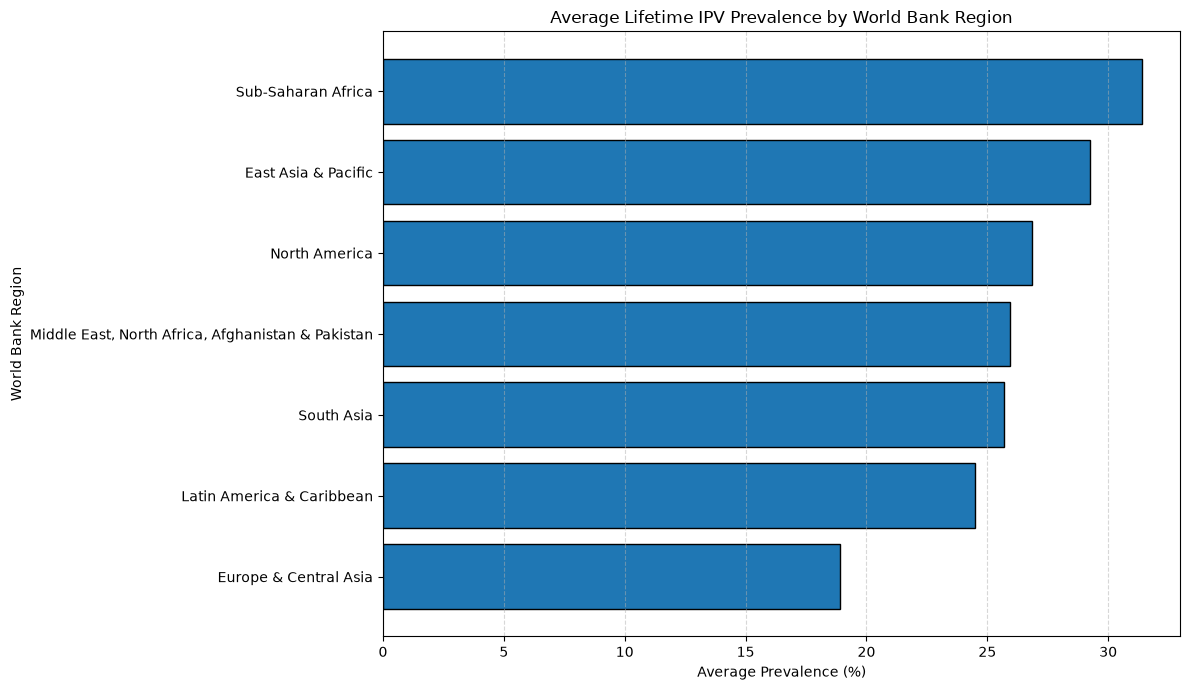

In [1974]:
import matplotlib.pyplot as plt

regional_means = regional_stats.sort_values("mean", ascending=True)

plt.figure(figsize=(12, 7))

plt.barh(
    regional_means.index,
    regional_means["mean"],
    edgecolor="black"
)

plt.title("Average Lifetime IPV Prevalence by World Bank Region")
plt.xlabel("Average Prevalence (%)")
plt.ylabel("World Bank Region")

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    "outputs/figures/06_regional_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 1400x800 with 0 Axes>

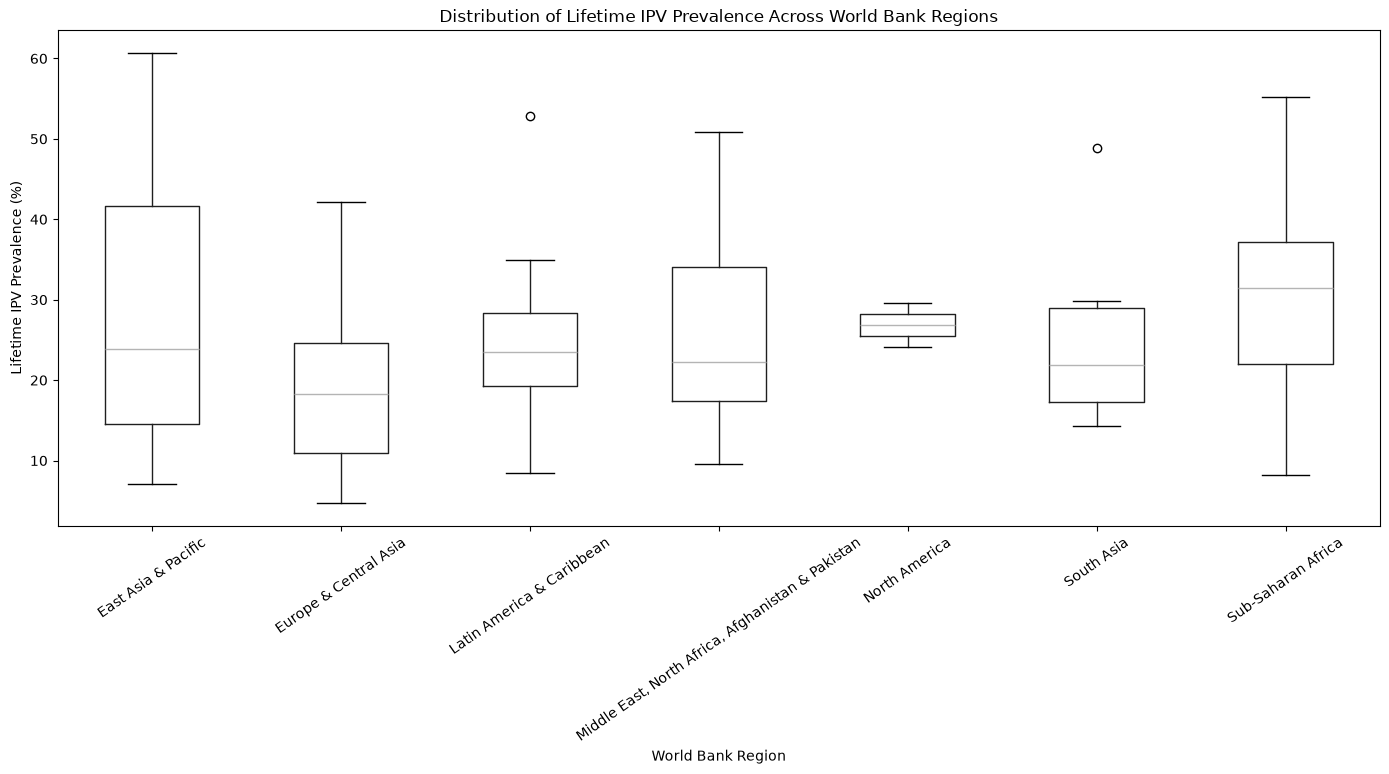

In [1975]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))

riha_regional.boxplot(
    column="Value",
    by="Region",
    grid=False,
    rot=35,
    figsize=(14, 8)
)

plt.title("Distribution of Lifetime IPV Prevalence Across World Bank Regions")
plt.suptitle("")
plt.xlabel("World Bank Region")
plt.ylabel("Lifetime IPV Prevalence (%)")
plt.tight_layout()

plt.savefig(
    "outputs/figures/07_regional_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The regional box plot illustrates the variation in lifetime intimate partner violence prevalence among countries within each World Bank region. It provides information about the median, spread, and potential outliers in the country-level estimates. The visualization helps identify regions with greater differences between countries and regions with relatively concentrated values. These variations highlight that countries within the same geographical region do not necessarily experience similar prevalence levels.


In [1976]:
regional_range = riha_regional.groupby("Region")["Value"].agg(
    ["min", "max"]
)

regional_range["Range"] = (
    regional_range["max"] - regional_range["min"]
)

regional_range = regional_range.sort_values(
    by="Range",
    ascending=False
)

print("REGIONAL PREVALENCE RANGE ANALYSIS")
print(regional_range.round(2))

REGIONAL PREVALENCE RANGE ANALYSIS
                                                    min   max  Range
Region                                                              
East Asia & Pacific                                 7.1  60.7   53.6
Sub-Saharan Africa                                  8.2  55.2   47.0
Latin America & Caribbean                           8.4  52.8   44.4
Middle East, North Africa, Afghanistan & Pakistan   9.6  50.9   41.3
Europe & Central Asia                               4.7  42.2   37.5
South Asia                                         14.3  48.9   34.6
North America                                      24.1  29.6    5.5


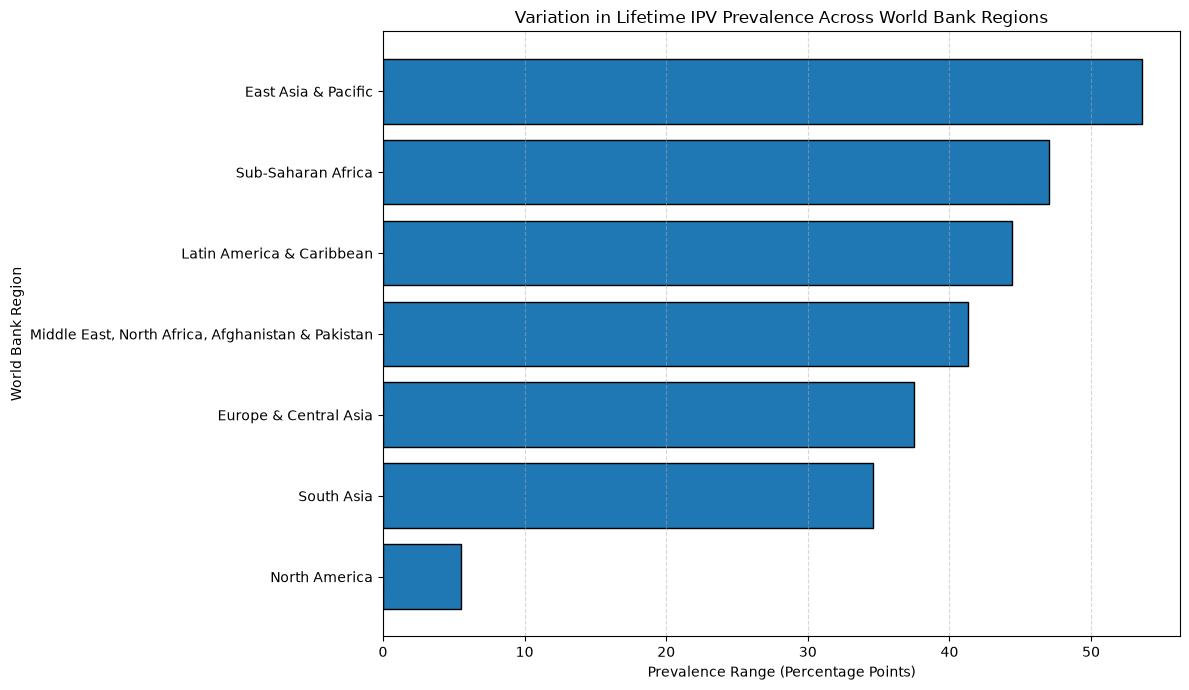

In [1977]:
import matplotlib.pyplot as plt

regional_range_sorted = regional_range.sort_values(
    by="Range",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    regional_range_sorted.index,
    regional_range_sorted["Range"],
    edgecolor="black"
)

plt.title("Variation in Lifetime IPV Prevalence Across World Bank Regions")
plt.xlabel("Prevalence Range (Percentage Points)")
plt.ylabel("World Bank Region")

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()

plt.savefig(
    "outputs/figures/08_regional_prevalence_range.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The regional range analysis identified substantial differences in country-level lifetime IPV prevalence estimates within several World Bank regions. East Asia & Pacific recorded the widest range of 53.6 percentage points, followed by Sub-Saharan Africa at 47.0 percentage points. North America recorded the smallest range of 5.5 percentage points; however, this result is based on only two countries. These findings demonstrate variation between countries within geographical regions and highlight the importance of examining individual country estimates alongside regional averages.


In [1978]:
regional_outliers = []

for region in riha_regional["Region"].unique():
    region_data = riha_regional[
        riha_regional["Region"] == region
    ]

    q1 = region_data["Value"].quantile(0.25)
    q3 = region_data["Value"].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = region_data[
        (region_data["Value"] < lower_bound) |
        (region_data["Value"] > upper_bound)
    ]

    for _, row in outliers.iterrows():
        regional_outliers.append({
            "Region": region,
            "Country": row["Country Name"],
            "Prevalence": row["Value"]
        })

outlier_df = pd.DataFrame(regional_outliers)

print("REGIONAL OUTLIER ANALYSIS")
print(outlier_df.to_string(index=False))

print("\nTotal potential outliers:", len(outlier_df))

REGIONAL OUTLIER ANALYSIS
                   Region    Country  Prevalence
Latin America & Caribbean    Bolivia        52.8
               South Asia Bangladesh        48.9

Total potential outliers: 2


The regional outlier analysis was conducted using the Interquartile Range (IQR) method, with the standard 1.5 × IQR rule. Two potential outliers were identified: Bolivia (52.8%) in Latin America & Caribbean and Bangladesh (48.9%) in South Asia. These countries have higher lifetime intimate partner violence prevalence estimates compared with the typical distribution within their respective regions. These statistical outliers highlight country-level differences and should not be interpreted as evidence of specific causes.


In [1979]:
global_mean = df["Value"].mean()

df["Comparison with Global Average"] = df["Value"].apply(
    lambda x: "Above Global Average" if x > global_mean else "Below or Equal to Global Average"
)

comparison_counts = df["Comparison with Global Average"].value_counts()

print("GLOBAL AVERAGE:", round(global_mean, 2), "%")

print("\nCOUNTRY COMPARISON")
print(comparison_counts)

print("\nPERCENTAGE DISTRIBUTION")
print((comparison_counts / len(df) * 100).round(2))

GLOBAL AVERAGE: 25.59 %

COUNTRY COMPARISON
Comparison with Global Average
Below or Equal to Global Average    92
Above Global Average                70
Name: count, dtype: int64

PERCENTAGE DISTRIBUTION
Comparison with Global Average
Below or Equal to Global Average    56.79
Above Global Average                43.21
Name: count, dtype: float64


The country-level comparison was performed using the overall mean lifetime intimate partner violence prevalence of 25.59% as the reference point. Out of 162 countries, 70 countries (43.21%) recorded prevalence estimates above the global country-level average, while 92 countries (56.79%) recorded estimates below or equal to it. These findings show that a larger proportion of countries fall at or below the calculated average. However, this comparison represents an equal-weighted country-level analysis rather than a population-weighted global estimate.


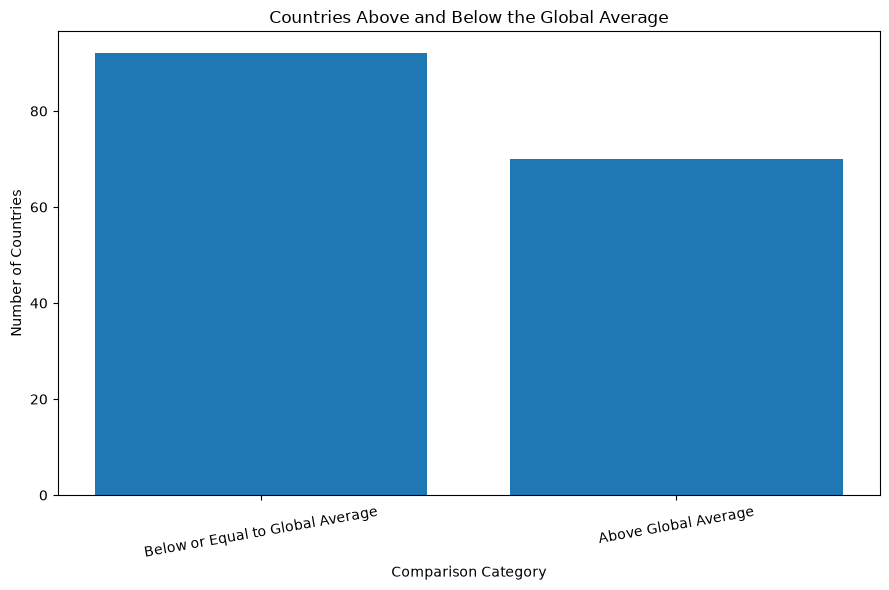

In [1980]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.bar(
    comparison_counts.index,
    comparison_counts.values
)

plt.title("Countries Above and Below the Global Average")
plt.xlabel("Comparison Category")
plt.ylabel("Number of Countries")
plt.xticks(rotation=10)
plt.tight_layout()

plt.savefig(
    "outputs/figures/09_global_average_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [1981]:
print("========== KEY ANALYTICAL INSIGHTS ==========")

print("\n1. Overall Average:")
print(round(df["Value"].mean(), 2), "%")

print("\n2. Highest Prevalence:")
print(df.loc[df["Value"].idxmax(), ["Country Name", "Value"]])

print("\n3. Lowest Prevalence:")
print(df.loc[df["Value"].idxmin(), ["Country Name", "Value"]])

print("\n4. Countries Above Global Average:")
print((df["Value"] > df["Value"].mean()).sum())

print("\n5. Highest Average Region:")
print(regional_stats["mean"].idxmax())

print("\n6. Lowest Average Region:")
print(regional_stats["mean"].idxmin())

print("\n7. Regional Outliers:")
print(len(outlier_df))

print("\n8. Prevalence Category Distribution:")
print(category_counts)

========== KEY ANALYTICAL INSIGHTS ==========

1. Overall Average:
25.59 %

2. Highest Prevalence:
Country Name    Fiji
Value           60.7
Name: 0, dtype: object

3. Lowest Prevalence:
Country Name    Kosovo
Value              4.7
Name: 161, dtype: object

4. Countries Above Global Average:
70

5. Highest Average Region:
Sub-Saharan Africa

6. Lowest Average Region:
Europe & Central Asia

7. Regional Outliers:
2

8. Prevalence Category Distribution:
Prevalence Category
Moderate    79
High        49
Low         34
Name: count, dtype: int64


1. The overall mean lifetime intimate partner violence prevalence across 162 countries was 25.59%.

2. Fiji recorded the highest prevalence estimate at 60.7%, while Kosovo recorded the lowest at 4.7%.

3. Sub-Saharan Africa had the highest regional average prevalence at 31.40%, whereas Europe & Central Asia had the lowest at 18.90%.

4. A total of 70 countries (43.21%) had prevalence estimates above the overall country-level average.

5. Based on the project's analytical categories, 79 countries were classified as Moderate, 49 as High, and 34 as Low.

6. Regional outlier analysis identified Bolivia (52.8%) and Bangladesh (48.9%) as potential statistical outliers.

7. The findings demonstrate considerable variation in lifetime IPV prevalence estimates across countries and regions.


In [1982]:
print("Total Regional Outliers:", len(outlier_df))
print(outlier_df)

Total Regional Outliers: 2
                      Region     Country  Prevalence
0  Latin America & Caribbean     Bolivia        52.8
1                 South Asia  Bangladesh        48.9


In [1983]:
import os

figure_folder = "outputs/figures"

figures = sorted(os.listdir(figure_folder))

print("TOTAL VISUALIZATIONS:", len(figures))

for figure in figures:
    print(figure)

TOTAL VISUALIZATIONS: 28
01_prevalence_distribution.png
02_top_10_countries.png
03_mean_vs_median.png
04_bottom_10_countries.png
05_prevalence_categories.png
06_regional_comparison.png
07_regional_boxplot.png
08_regional_prevalence_range.png
09_global_average_comparison.png
age_group_comparison.png
bottom10_countries.csv
bottom10_countries_chart.png
income_group_comparison.png
indicator_correlation_heatmap.png
indicator_relationship.png
prevalence_boxplot.png
prevalence_distribution.png
regional_prevalence.png
regional_violence_comparison.png
riha_key_findings.csv
riha_summary_statistics.csv
summary_statistics_chart.png
top10_countries.csv
top10_countries_chart.png
top10_countries_prevalence.png
top_10_lifetime_violence_estimates.png
top_10_recent_violence_estimates.png
violence_estimates_boxplot.png


In [1984]:
import os

report_folder = "reports"

print("REPORT FOLDER CONTENTS")

for item in os.listdir(report_folder):
    print(item)

REPORT FOLDER CONTENTS
